# Credit Card Users Churn Prediction

## Problem Statement

### Business Context

The Thera bank recently saw a steep decline in the number of users of their credit card, credit cards are a good source of income for banks because of different kinds of fees charged by the banks like annual fees, balance transfer fees, and cash advance fees, late payment fees, foreign transaction fees, and others. Some fees are charged to every user irrespective of usage, while others are charged under specified circumstances.

Customers’ leaving credit cards services would lead bank to loss, so the bank wants to analyze the data of customers and identify the customers who will leave their credit card services and reason for same – so that bank could improve upon those areas

You as a Data scientist at Thera bank need to come up with a classification model that will help the bank improve its services so that customers do not renounce their credit cards

### Data Description

* CLIENTNUM: Client number. Unique identifier for the customer holding the account
* Attrition_Flag: Internal event (customer activity) variable - if the account is closed then "Attrited Customer" else "Existing Customer"
* Customer_Age: Age in Years
* Gender: Gender of the account holder
* Dependent_count: Number of dependents
* Education_Level: Educational Qualification of the account holder - Graduate, High School, Unknown, Uneducated, College(refers to college student), Post-Graduate, Doctorate
* Marital_Status: Marital Status of the account holder
* Income_Category: Annual Income Category of the account holder
* Card_Category: Type of Card
* Months_on_book: Period of relationship with the bank (in months)
* Total_Relationship_Count: Total no. of products held by the customer
* Months_Inactive_12_mon: No. of months inactive in the last 12 months
* Contacts_Count_12_mon: No. of Contacts in the last 12 months
* Credit_Limit: Credit Limit on the Credit Card
* Total_Revolving_Bal: Total Revolving Balance on the Credit Card
* Avg_Open_To_Buy: Open to Buy Credit Line (Average of last 12 months)
* Total_Amt_Chng_Q4_Q1: Change in Transaction Amount (Q4 over Q1)
* Total_Trans_Amt: Total Transaction Amount (Last 12 months)
* Total_Trans_Ct: Total Transaction Count (Last 12 months)
* Total_Ct_Chng_Q4_Q1: Change in Transaction Count (Q4 over Q1)
* Avg_Utilization_Ratio: Average Card Utilization Ratio

#### What Is a Revolving Balance?

- If we don't pay the balance of the revolving credit account in full every month, the unpaid portion carries over to the next month. That's called a revolving balance


##### What is the Average Open to buy?

- 'Open to Buy' means the amount left on your credit card to use. Now, this column represents the average of this value for the last 12 months.

##### What is the Average utilization Ratio?

- The Avg_Utilization_Ratio represents how much of the available credit the customer spent. This is useful for calculating credit scores.


##### Relation b/w Avg_Open_To_Buy, Credit_Limit and Avg_Utilization_Ratio:

- ( Avg_Open_To_Buy / Credit_Limit ) + Avg_Utilization_Ratio = 1

## Importing necessary libraries

In [1]:
# Libraries used (versions this notebook was last run with). Uncomment to install.
# !pip install scikit-learn==1.8.0 xgboost==3.2.0 imbalanced-learn==0.14.2 pandas==3.0.1 numpy==2.4.2 seaborn==0.13.2 matplotlib==3.11.2 -q

In [2]:
# Data handling
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore")

# Splitting, cross-validation and tuning
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)

# Pre-processing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Imbalance handling (resampling happens inside each training fold)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

# Models
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
from xgboost import XGBClassifier

# Metrics
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)

## Loading the dataset

In [3]:
# Load the dataset (the CSV sits next to this notebook)
BankChurners = pd.read_csv("BankChurners.csv")

## Data Overview

- Observations
- Sanity checks

In [4]:
# Checking first 5 rows of the data
BankChurners.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [5]:
# Checking last 5 rows of the data
BankChurners.tail()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,3,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,710638233,Attrited Customer,41,M,2,NaN,Divorced,$40K - $60K,Blue,25,4,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,5,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,717406983,Attrited Customer,30,M,2,Graduate,NaN,$40K - $60K,Blue,36,4,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000
10126,714337233,Attrited Customer,43,F,2,Graduate,Married,Less than $40K,Silver,25,6,2,4,10388.0,1961,8427.0,0.703,10294,61,0.649,0.189


In [6]:
# To check the number of rows and columns present in the dataset
BankChurners.shape

(10127, 21)

In [7]:
# To check the data type of features present
BankChurners.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CLIENTNUM                 10127 non-null  int64  
 1   Attrition_Flag            10127 non-null  str    
 2   Customer_Age              10127 non-null  int64  
 3   Gender                    10127 non-null  str    
 4   Dependent_count           10127 non-null  int64  
 5   Education_Level           8608 non-null   str    
 6   Marital_Status            9378 non-null   str    
 7   Income_Category           10127 non-null  str    
 8   Card_Category             10127 non-null  str    
 9   Months_on_book            10127 non-null  int64  
 10  Total_Relationship_Count  10127 non-null  int64  
 11  Months_Inactive_12_mon    10127 non-null  int64  
 12  Contacts_Count_12_mon     10127 non-null  int64  
 13  Credit_Limit              10127 non-null  float64
 14  Total_Revolving_B

In [8]:
# To check the missing data present in each feature if present
BankChurners.isna().sum()

CLIENTNUM                      0
Attrition_Flag                 0
Customer_Age                   0
Gender                         0
Dependent_count                0
Education_Level             1519
Marital_Status               749
Income_Category                0
Card_Category                  0
Months_on_book                 0
Total_Relationship_Count       0
Months_Inactive_12_mon         0
Contacts_Count_12_mon          0
Credit_Limit                   0
Total_Revolving_Bal            0
Avg_Open_To_Buy                0
Total_Amt_Chng_Q4_Q1           0
Total_Trans_Amt                0
Total_Trans_Ct                 0
Total_Ct_Chng_Q4_Q1            0
Avg_Utilization_Ratio          0
dtype: int64

In [9]:
# To check the total number of duplicated rows present in the dataset
duplicated_rows=BankChurners[BankChurners.duplicated()]
duplicated_rows.shape[0]

0

In [10]:
# To check the summary statistics
BankChurners.describe()

,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000


In [11]:
for i in BankChurners.select_dtypes(exclude="number").columns:
    print("Unique values in", i, "are :")
    print(BankChurners[i].value_counts(dropna=False))
    print("*" * 50)

Unique values in Attrition_Flag are :
Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64
**************************************************
Unique values in Gender are :
Gender
F    5358
M    4769
Name: count, dtype: int64
**************************************************
Unique values in Education_Level are :
Education_Level
Graduate         3128
High School      2013
NaN              1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64
**************************************************
Unique values in Marital_Status are :
Marital_Status
Married     4687
Single      3943
NaN          749
Divorced     748
Name: count, dtype: int64
**************************************************
Unique values in Income_Category are :
Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
abc               1112
$120K +            727
Name: c

### Data Overview Findings:

1. **Dataset Size**: The dataset contains 10,127 entries and 21 columns.

2. **Missing Values**:
   - Columns 'Education_Level' and 'Marital_Status' have missing values.
   - 'Education_Level' has 1,519 missing values.
   - 'Marital_Status' has 749 missing values.

3. **Duplicate Rows**: There are no duplicate rows in the dataset.

4. **Data Types**:
   - 5 columns are of float64 type.
   - 10 columns are of int64 type.
   - 6 columns are of object type.

5. **Summary Statistics**:
   - Customer age ranges from 26 to 73 years, with a mean of approximately 46 years.
   - Average dependent count is around 2.35.
   - Average months on book (relationship with the bank) is approximately 36 months.
   - Average credit limit is around 8,632.
   - Average total revolving balance is approximately 1,163.
   - Average total transaction amount in the last 12 months is approximately $4,404.
   - Average total transaction count in the last 12 months is around 65.
   - Average utilization ratio is about 0.27.

6. **Unique Values**:
   - **Attrition_Flag**:
     - 8,500 entries represent existing customers.
     - 1,627 entries represent attrited customers.
   - **Gender**:
     - 5,358 entries are labeled as Female.
     - 4,769 entries are labeled as Male.
   - **Education_Level**:
     - Most common education level is Graduate with 3,128 entries.
   - **Marital_Status**:
     - Majority of customers are Married, with 4,687 entries.
   - **Income_Category**:
     - Most customers fall under the income category of 'Less than $40K' with 3,561 entries.
   - **Card_Category**:
     - Blue card is the most common card category, with 9,436 entries.



## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. How is the total transaction amount distributed?
2. What is the distribution of the level of education of customers?
3. What is the distribution of the level of income of customers?
4. How does the change in transaction amount between Q4 and Q1 (`total_ct_change_Q4_Q1`) vary by the customer's account status (`Attrition_Flag`)?
5. How does the number of months a customer was inactive in the last 12 months (`Months_Inactive_12_mon`) vary by the customer's account status (`Attrition_Flag`)?
6. What are the attributes that have a strong correlation with each other?



#### The below functions need to be defined to carry out the Exploratory Data Analysis.

In [12]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [13]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

In [14]:
# function to plot stacked bar chart

def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 1, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

In [15]:
### Function to plot distributions

def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

### Univariate analysis

`Customer_Age`

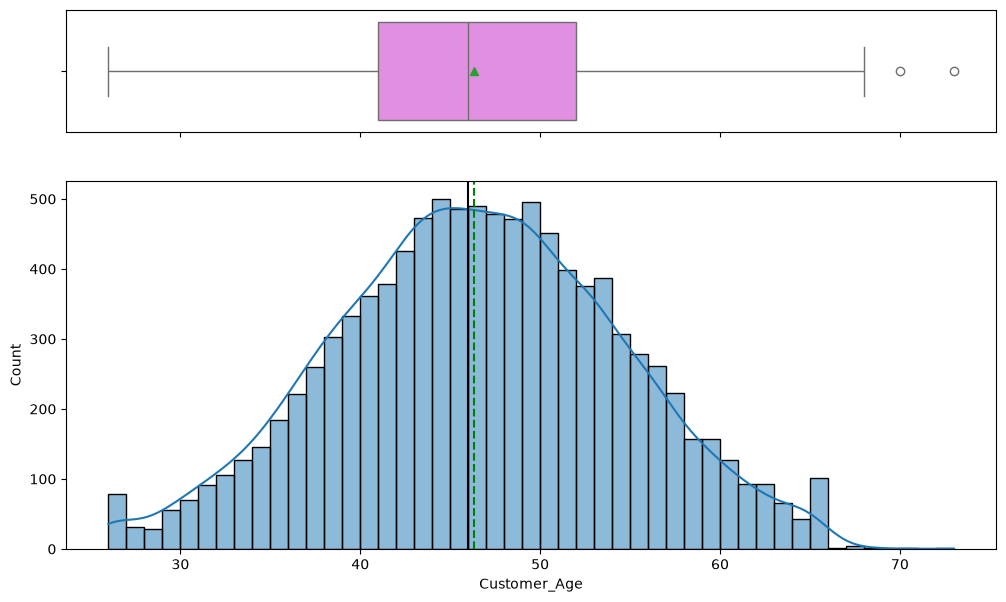

In [16]:
histogram_boxplot(BankChurners, "Customer_Age", kde=True)

`Months_on_book`

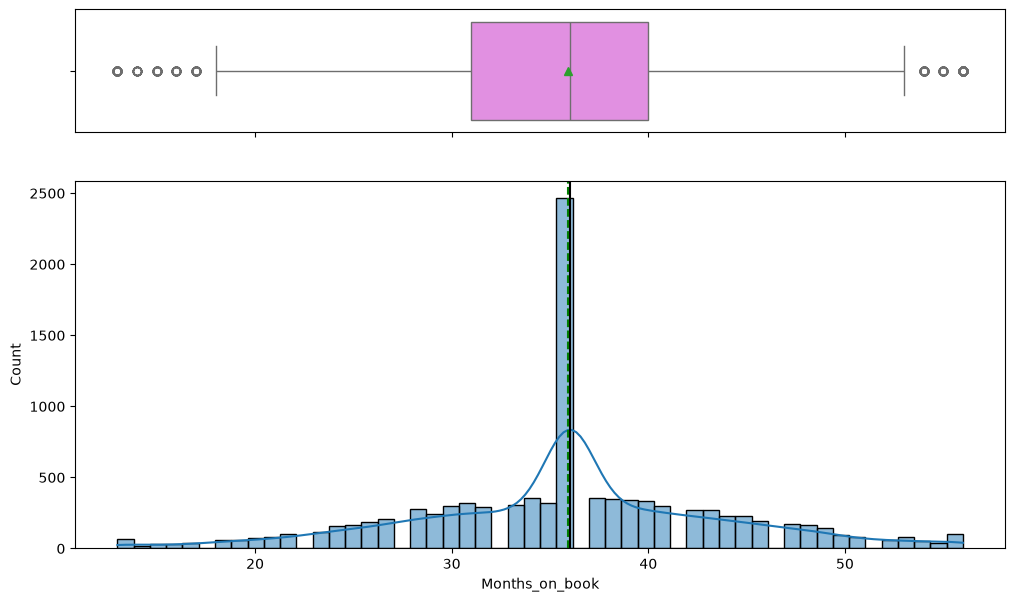

In [17]:
histogram_boxplot(BankChurners, "Months_on_book", kde=True)

Credit_Limit

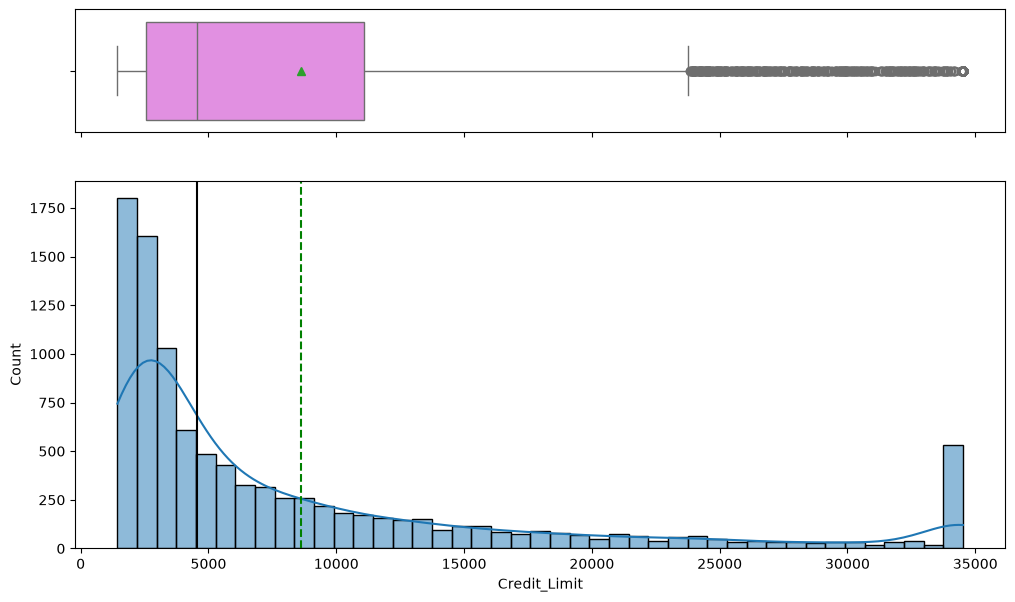

In [18]:
histogram_boxplot(BankChurners, "Credit_Limit", kde=True)

Total_Revolving_Bal

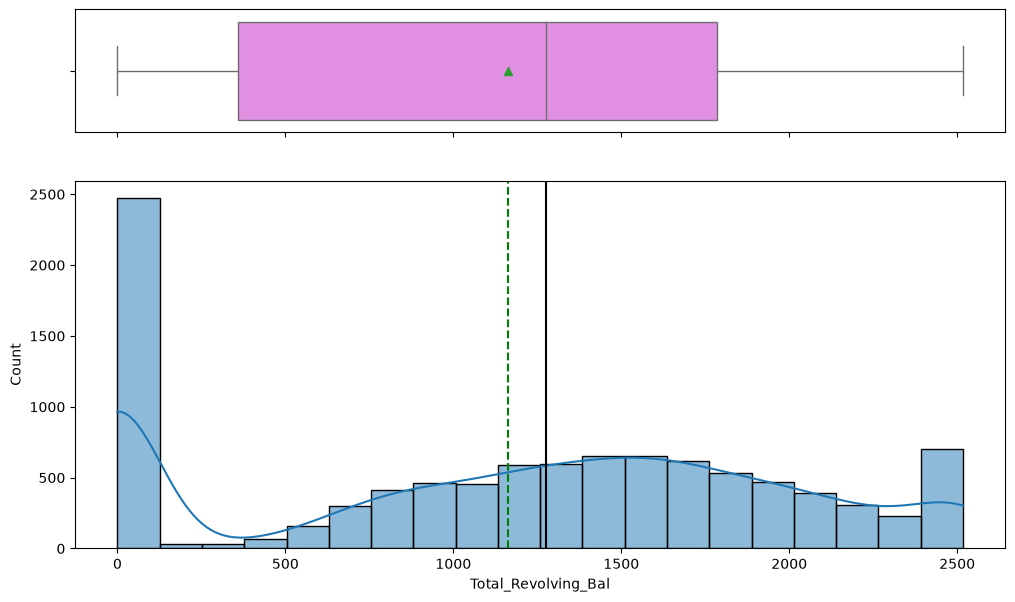

In [19]:
histogram_boxplot(BankChurners, "Total_Revolving_Bal", kde=True)

Avg_Open_To_Buy

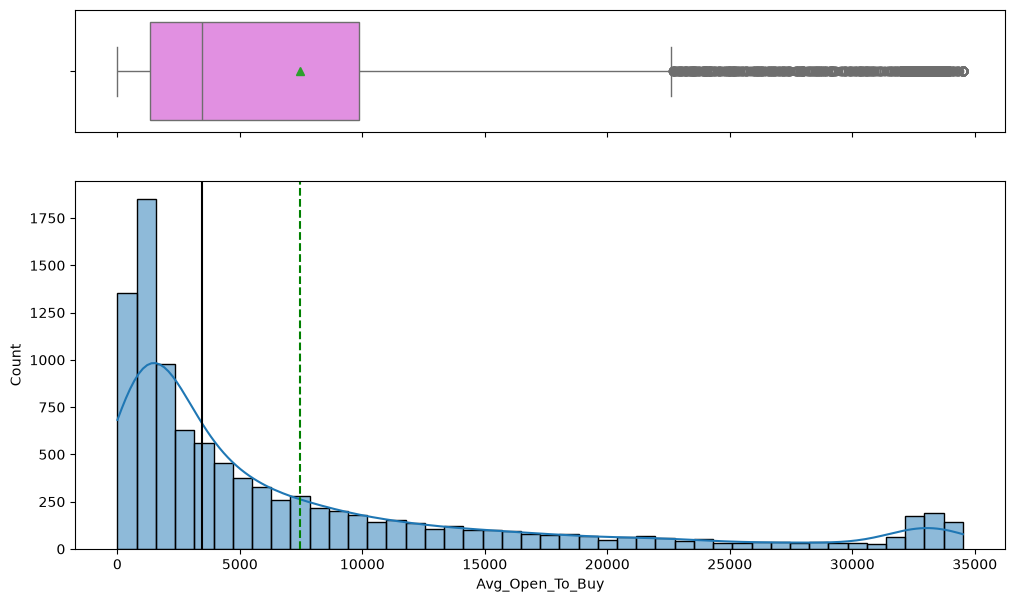

In [20]:
histogram_boxplot(BankChurners, "Avg_Open_To_Buy", kde=True)

Total_Trans_Ct

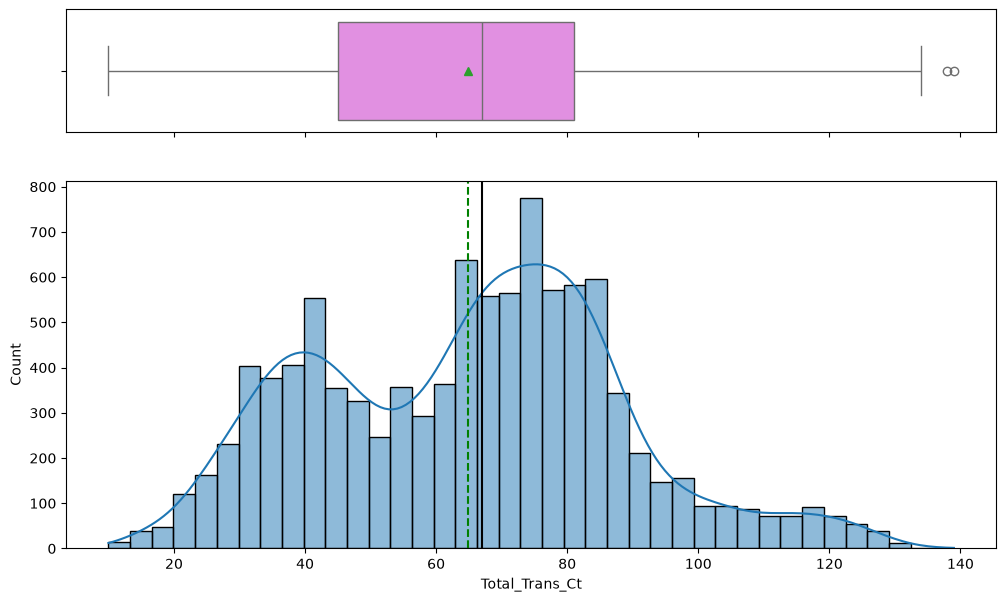

In [21]:
histogram_boxplot(BankChurners, "Total_Trans_Ct", kde=True)

Total_Amt_Chng_Q4_Q1

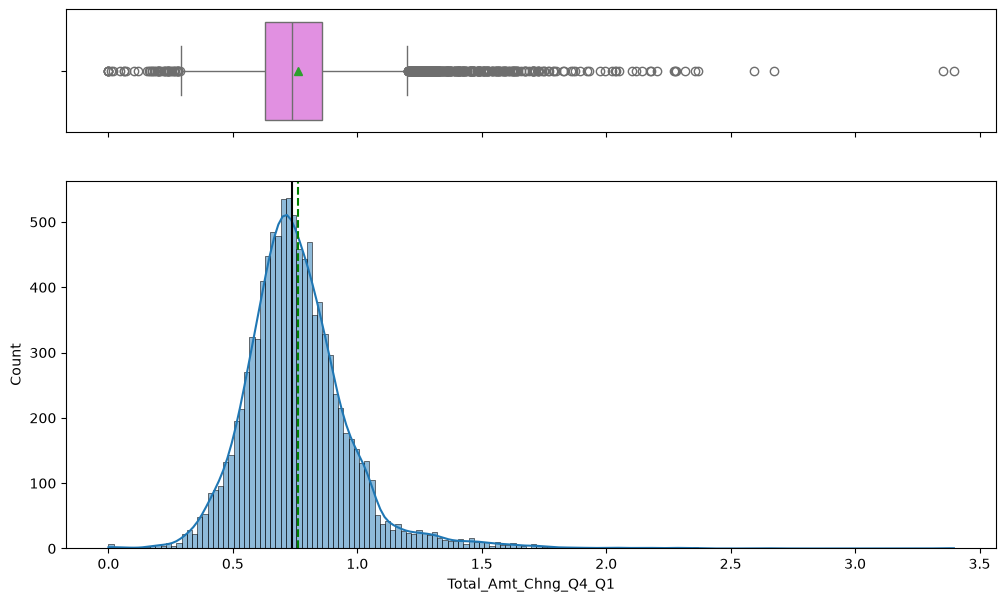

In [22]:
histogram_boxplot(BankChurners, "Total_Amt_Chng_Q4_Q1", kde=True)

`Total_Trans_Amt`

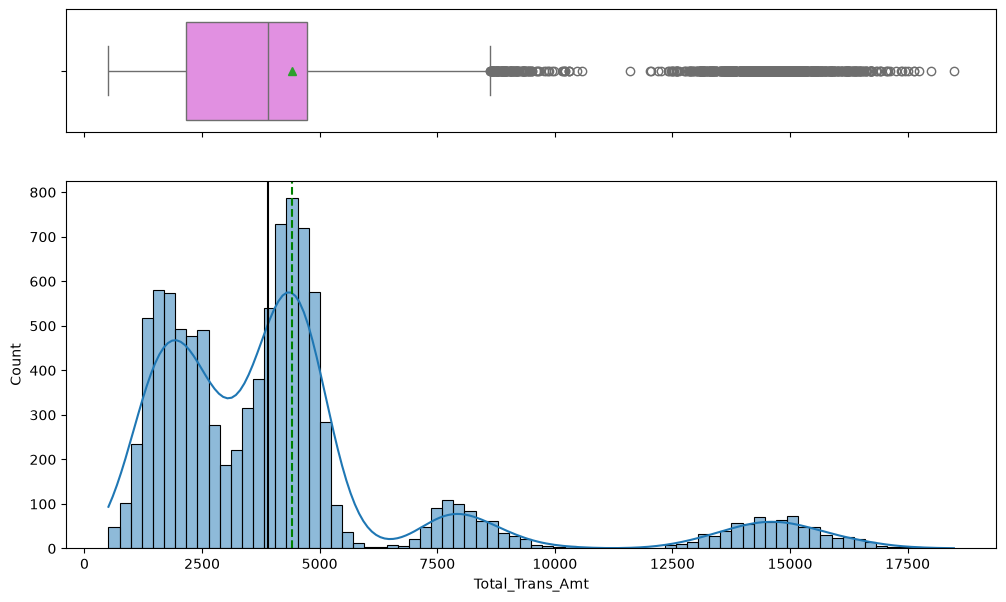

In [23]:
histogram_boxplot(BankChurners, "Total_Trans_Amt", kde=True)

Total_Ct_Chng_Q4_Q1

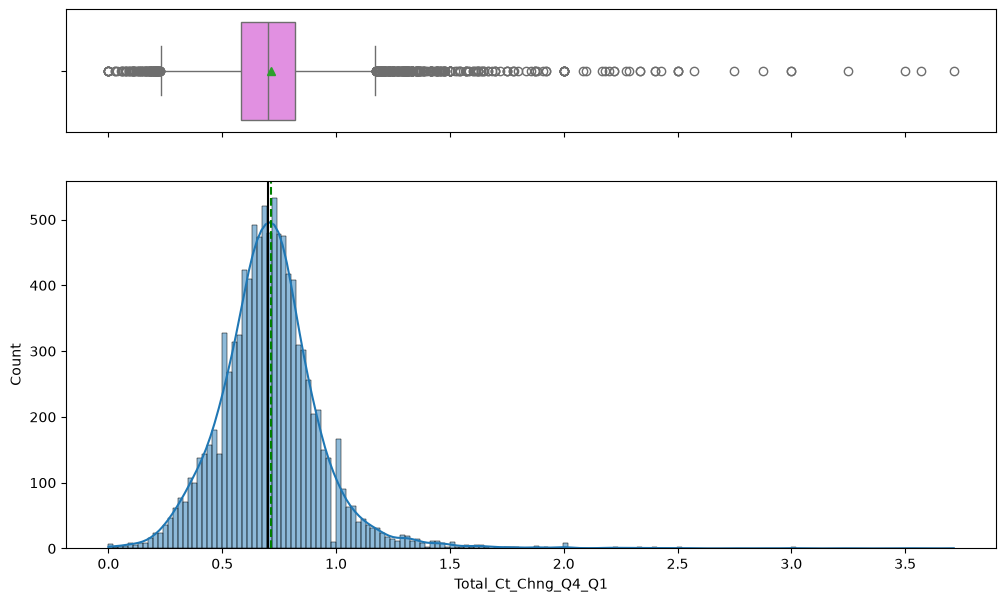

In [24]:
histogram_boxplot(BankChurners, "Total_Ct_Chng_Q4_Q1", kde=True)

Avg_Utilization_Ratio

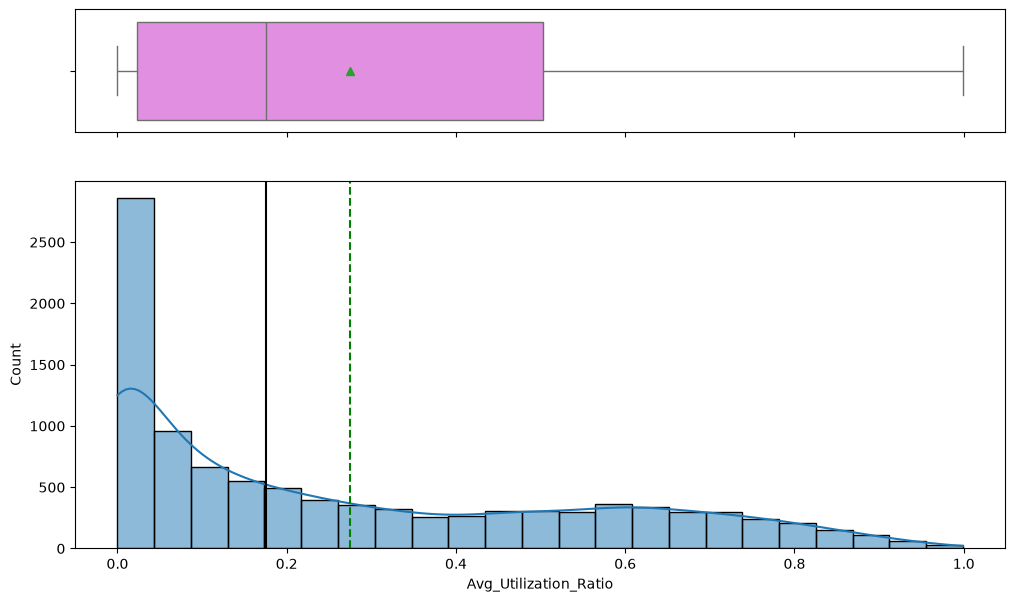

In [25]:
histogram_boxplot(BankChurners, "Avg_Utilization_Ratio", kde=True)

Dependent_count

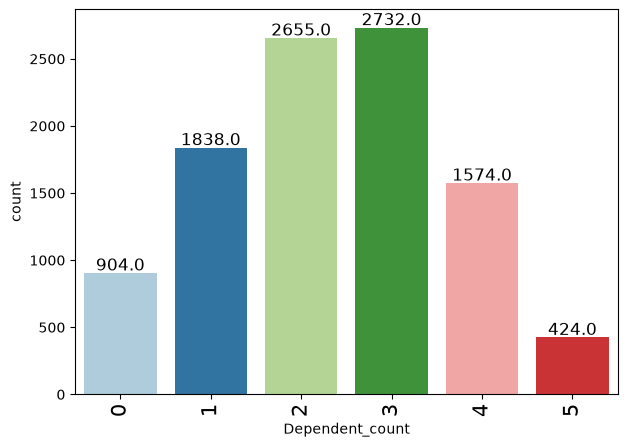

In [26]:
labeled_barplot(BankChurners, "Dependent_count")

Total_Relationship_Count

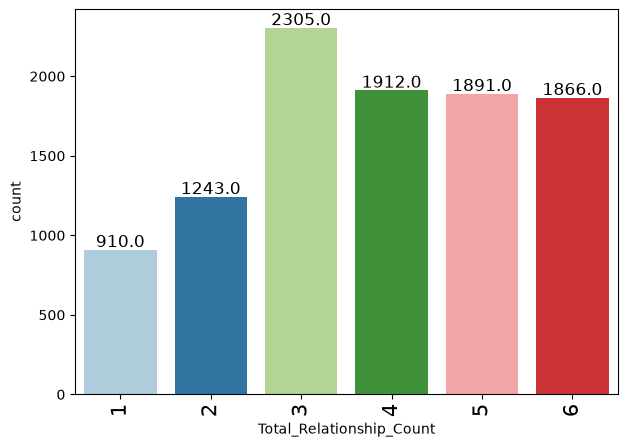

In [27]:
labeled_barplot(BankChurners, "Total_Relationship_Count")

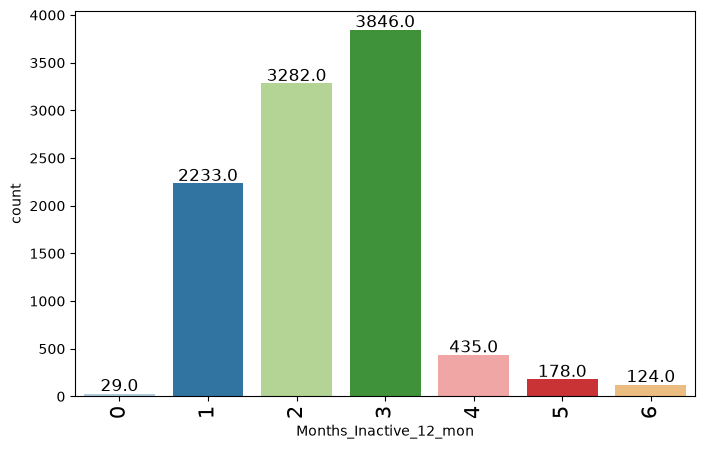

In [28]:
labeled_barplot(BankChurners, "Months_Inactive_12_mon")

Contacts_Count_12_mon

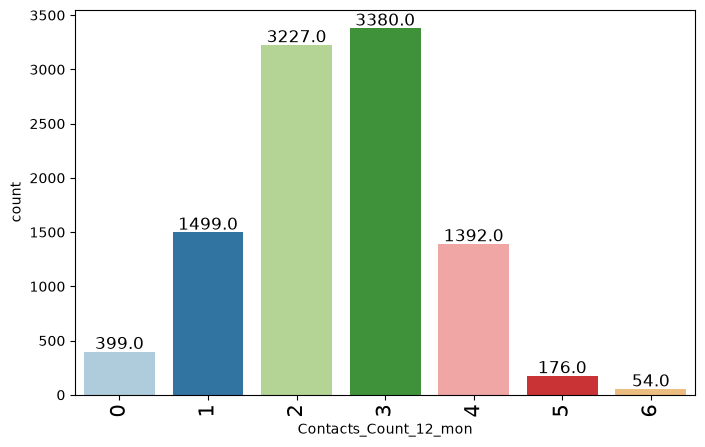

In [29]:
labeled_barplot(BankChurners, "Contacts_Count_12_mon")

Gender

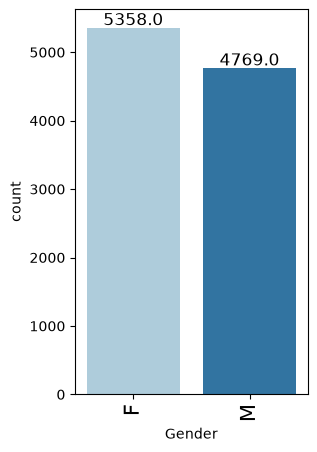

In [30]:
labeled_barplot(BankChurners, "Gender")

`Education_Level`

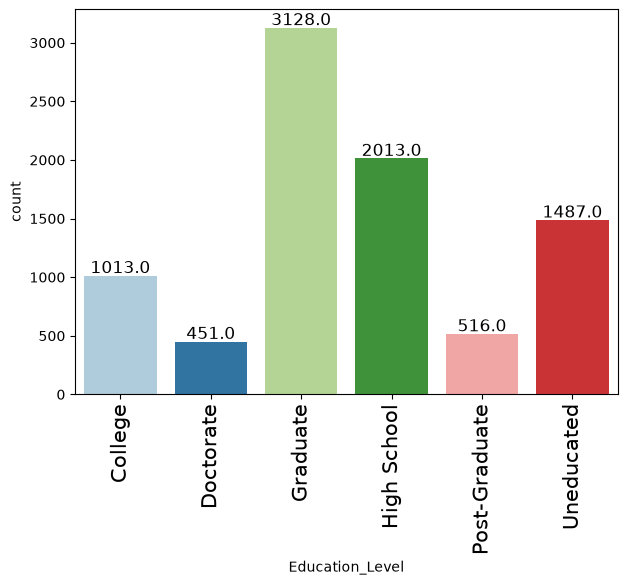

In [31]:
labeled_barplot(BankChurners, "Education_Level")

Marital_Status

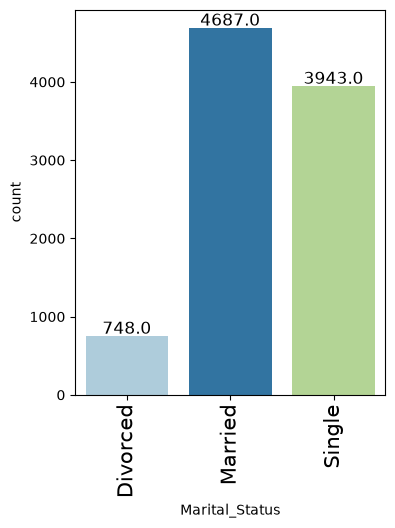

In [32]:
labeled_barplot(BankChurners, "Marital_Status")

Income_Category

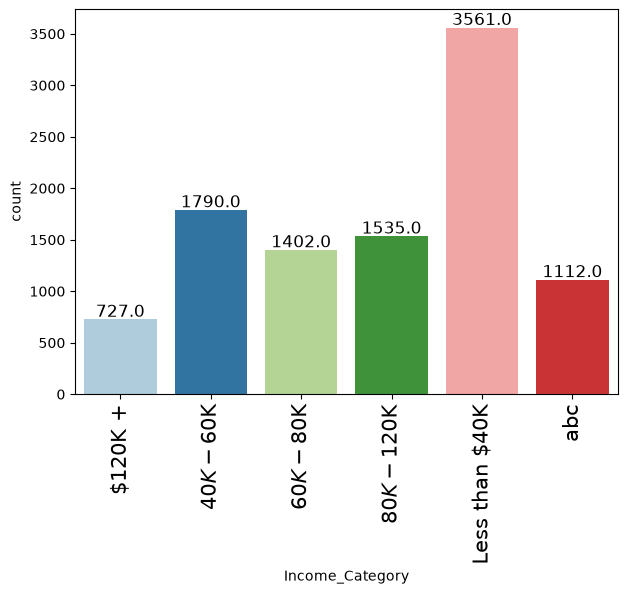

In [33]:
labeled_barplot(BankChurners, "Income_Category")

Card_Category

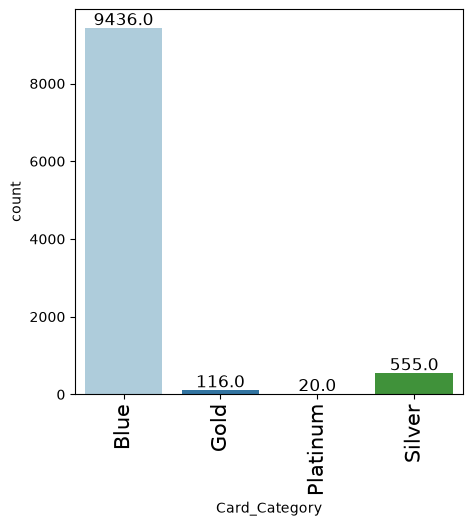

In [34]:
labeled_barplot(BankChurners, "Card_Category")

Attrition_Flag

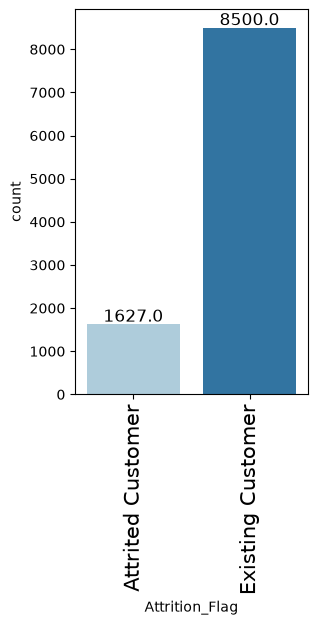

In [35]:
labeled_barplot(BankChurners, "Attrition_Flag")

### Findings from univariate analysis
- **Age** is roughly normal around 46 years (26 to 73), with a few outliers at the top.
- **Months on book** peaks sharply at 36 months: many accounts were opened in the same period, otherwise roughly normal.
- **Credit limit, open-to-buy and transaction amount** are right-skewed: most customers have modest limits and spend, with a long tail of high values (credit limits are capped near 34,500).
- **Revolving balance** has a large spike at 0 (customers who pay in full) and another near the 2,517 cap.
- **Transaction count** is bimodal, with peaks around 40 and 75 transactions a year.
- **Q4 to Q1 change ratios** cluster below 1, so spending and transaction counts usually fall from Q4 to Q1.
- **Utilisation ratio** is mostly low, with a spike at 0.
- **Dependents:** 2 or 3 is most common. **Products held:** 3 is most common.
- **Inactivity:** most customers were inactive for 1 to 3 months in the last year. **Contacts:** 2 or 3 contacts is most common.
- **Gender:** slightly more women (5,358) than men (4,769).
- **Education:** Graduate is the most common level, Doctorate the rarest; 1,519 customers have no recorded education.
- **Marital status:** mostly married, then single; 749 not recorded.
- **Income:** the largest group earns **less than $40K** (3,561); 1,112 rows hold the placeholder `abc`, which is treated as missing.
- **Card:** 93% of customers hold the Blue card; Platinum has only 20 holders.
- **Target:** 16.1% of customers churned (1,627 of 10,127), so the classes are imbalanced.

### Bivariate Distributions

Attrition_Flag vs Gender

Attrition_Flag  Attrited Customer  Existing Customer    All
Gender                                                     
All                          1627               8500  10127
F                             930               4428   5358
M                             697               4072   4769
------------------------------------------------------------------------------------------------------------------------


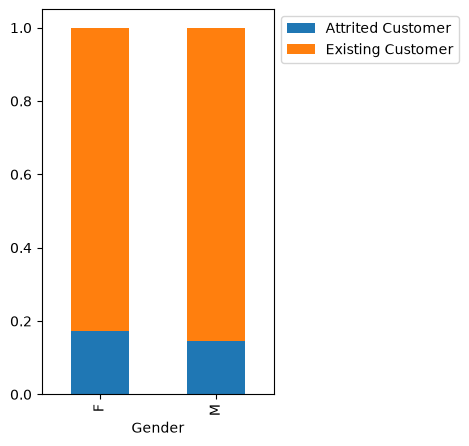

In [36]:
stacked_barplot(BankChurners, "Gender", "Attrition_Flag")

`Attrition_Flag vs Marital_Status`

Attrition_Flag  Attrited Customer  Existing Customer   All
Marital_Status                                            
All                          1498               7880  9378
Married                       709               3978  4687
Single                        668               3275  3943
Divorced                      121                627   748
------------------------------------------------------------------------------------------------------------------------


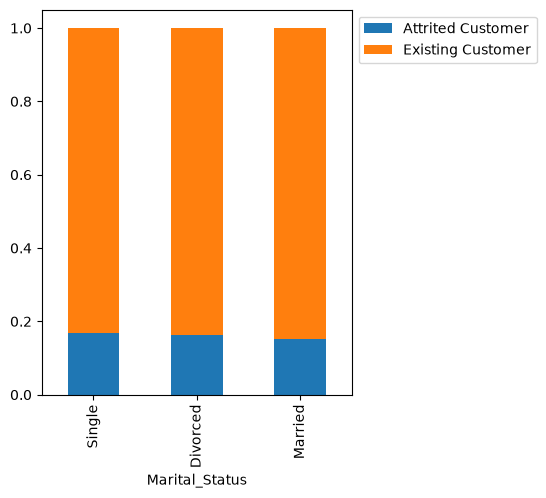

In [37]:
stacked_barplot(BankChurners,"Marital_Status","Attrition_Flag")

Attrition_Flag vs Education_Level

Attrition_Flag   Attrited Customer  Existing Customer   All
Education_Level                                            
All                           1371               7237  8608
Graduate                       487               2641  3128
High School                    306               1707  2013
Uneducated                     237               1250  1487
College                        154                859  1013
Doctorate                       95                356   451
Post-Graduate                   92                424   516
------------------------------------------------------------------------------------------------------------------------


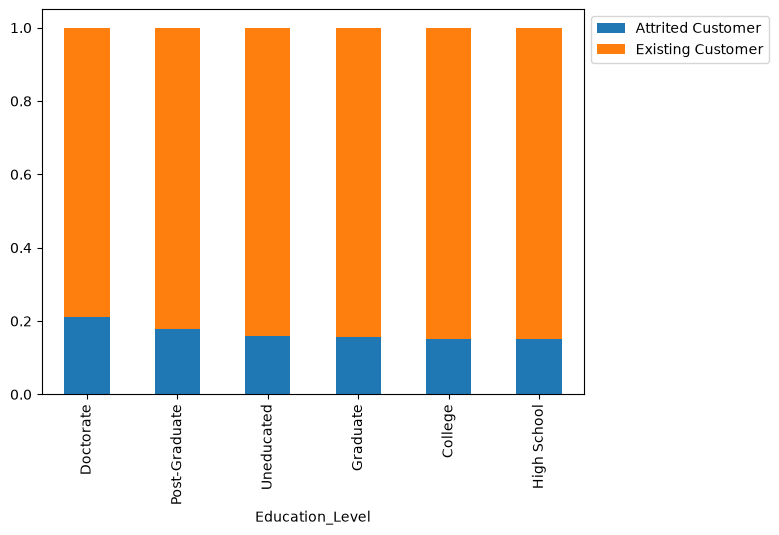

In [38]:
stacked_barplot(BankChurners, "Education_Level", "Attrition_Flag")

Attrition_Flag vs Income_Category

Attrition_Flag   Attrited Customer  Existing Customer    All
Income_Category                                             
All                           1627               8500  10127
Less than $40K                 612               2949   3561
$40K - $60K                    271               1519   1790
$80K - $120K                   242               1293   1535
$60K - $80K                    189               1213   1402
abc                            187                925   1112
$120K +                        126                601    727
------------------------------------------------------------------------------------------------------------------------


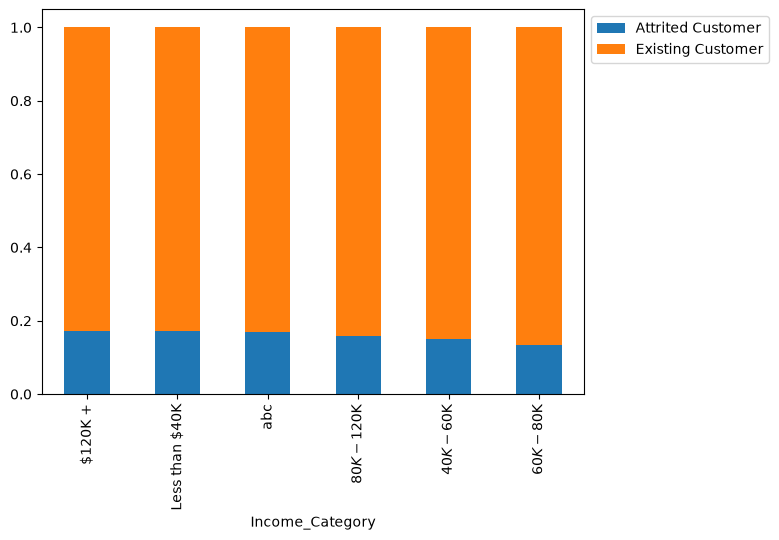

In [39]:
stacked_barplot(BankChurners, "Income_Category", "Attrition_Flag")

Attrition_Flag vs Contacts_Count_12_mon

Attrition_Flag         Attrited Customer  Existing Customer    All
Contacts_Count_12_mon                                             
All                                 1627               8500  10127
3                                    681               2699   3380
2                                    403               2824   3227
4                                    315               1077   1392
1                                    108               1391   1499
5                                     59                117    176
6                                     54                  0     54
0                                      7                392    399
------------------------------------------------------------------------------------------------------------------------


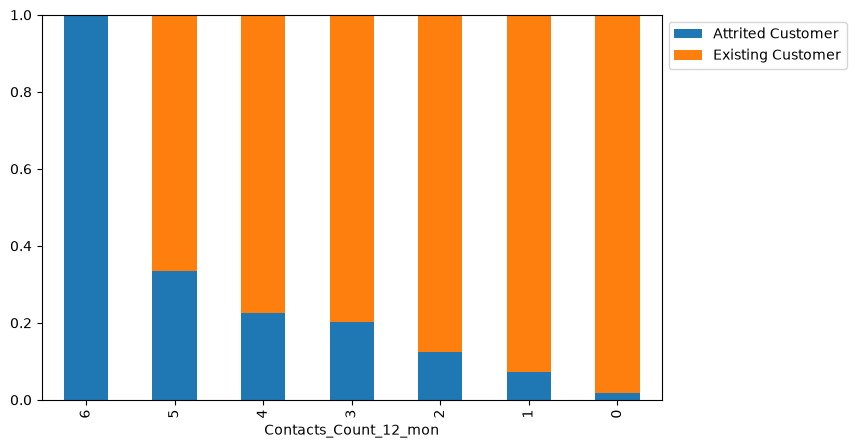

In [40]:
stacked_barplot(BankChurners, "Contacts_Count_12_mon", "Attrition_Flag")

Attrition_Flag vs Months_Inactive_12_mon

Attrition_Flag          Attrited Customer  Existing Customer    All
Months_Inactive_12_mon                                             
All                                  1627               8500  10127
3                                     826               3020   3846
2                                     505               2777   3282
4                                     130                305    435
1                                     100               2133   2233
5                                      32                146    178
6                                      19                105    124
0                                      15                 14     29
------------------------------------------------------------------------------------------------------------------------


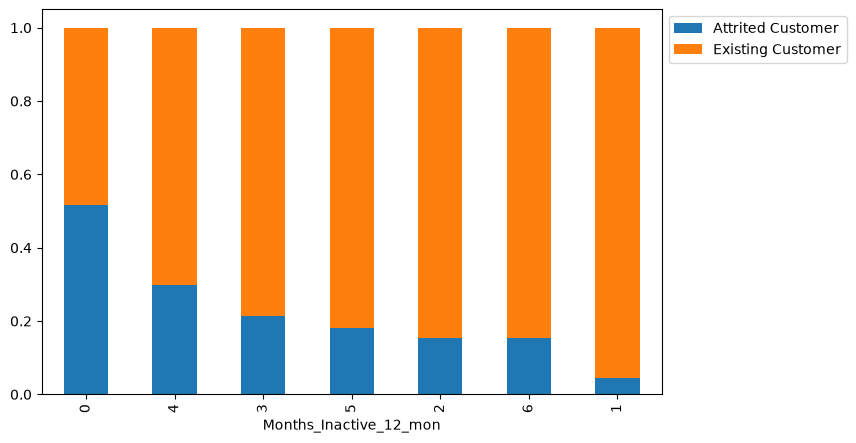

In [41]:
stacked_barplot(BankChurners, "Months_Inactive_12_mon", "Attrition_Flag")

Attrition_Flag vs Total_Relationship_Count

Attrition_Flag            Attrited Customer  Existing Customer    All
Total_Relationship_Count                                             
All                                    1627               8500  10127
3                                       400               1905   2305
2                                       346                897   1243
1                                       233                677    910
5                                       227               1664   1891
4                                       225               1687   1912
6                                       196               1670   1866
------------------------------------------------------------------------------------------------------------------------


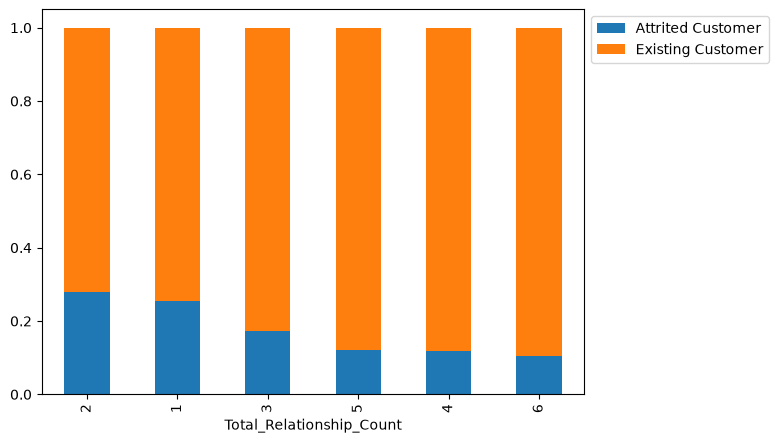

In [42]:
stacked_barplot(BankChurners, "Total_Relationship_Count", "Attrition_Flag")

Attrition_Flag vs Dependent_count

Attrition_Flag   Attrited Customer  Existing Customer    All
Dependent_count                                             
All                           1627               8500  10127
3                              482               2250   2732
2                              417               2238   2655
1                              269               1569   1838
4                              260               1314   1574
0                              135                769    904
5                               64                360    424
------------------------------------------------------------------------------------------------------------------------


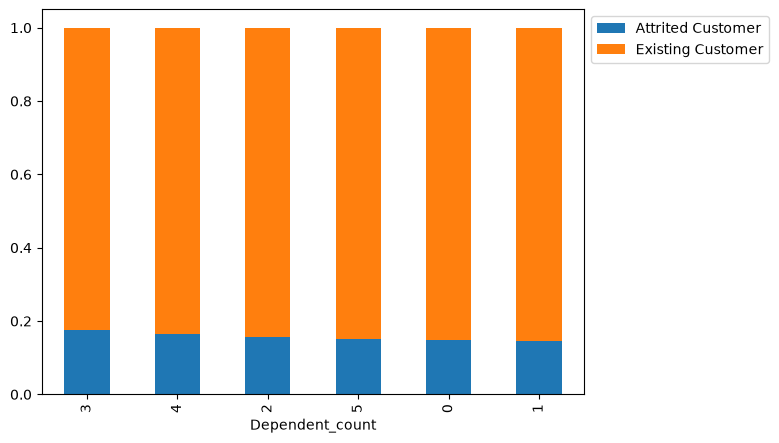

In [43]:
stacked_barplot(BankChurners, "Dependent_count", "Attrition_Flag")

Total_Revolving_Bal vs Attrition_Flag

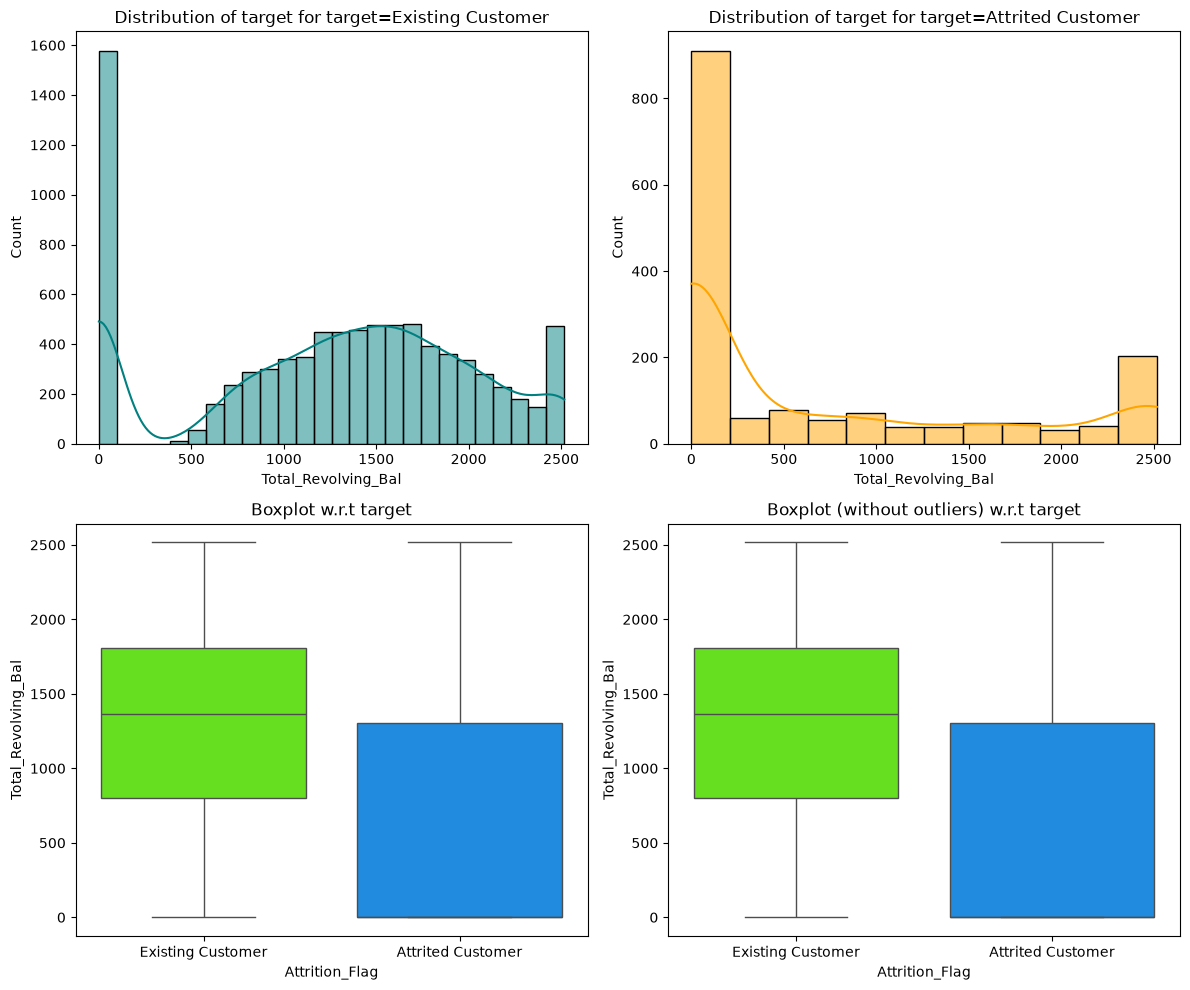

In [44]:
distribution_plot_wrt_target(BankChurners, "Total_Revolving_Bal", "Attrition_Flag")

Attrition_Flag vs Credit_Limit

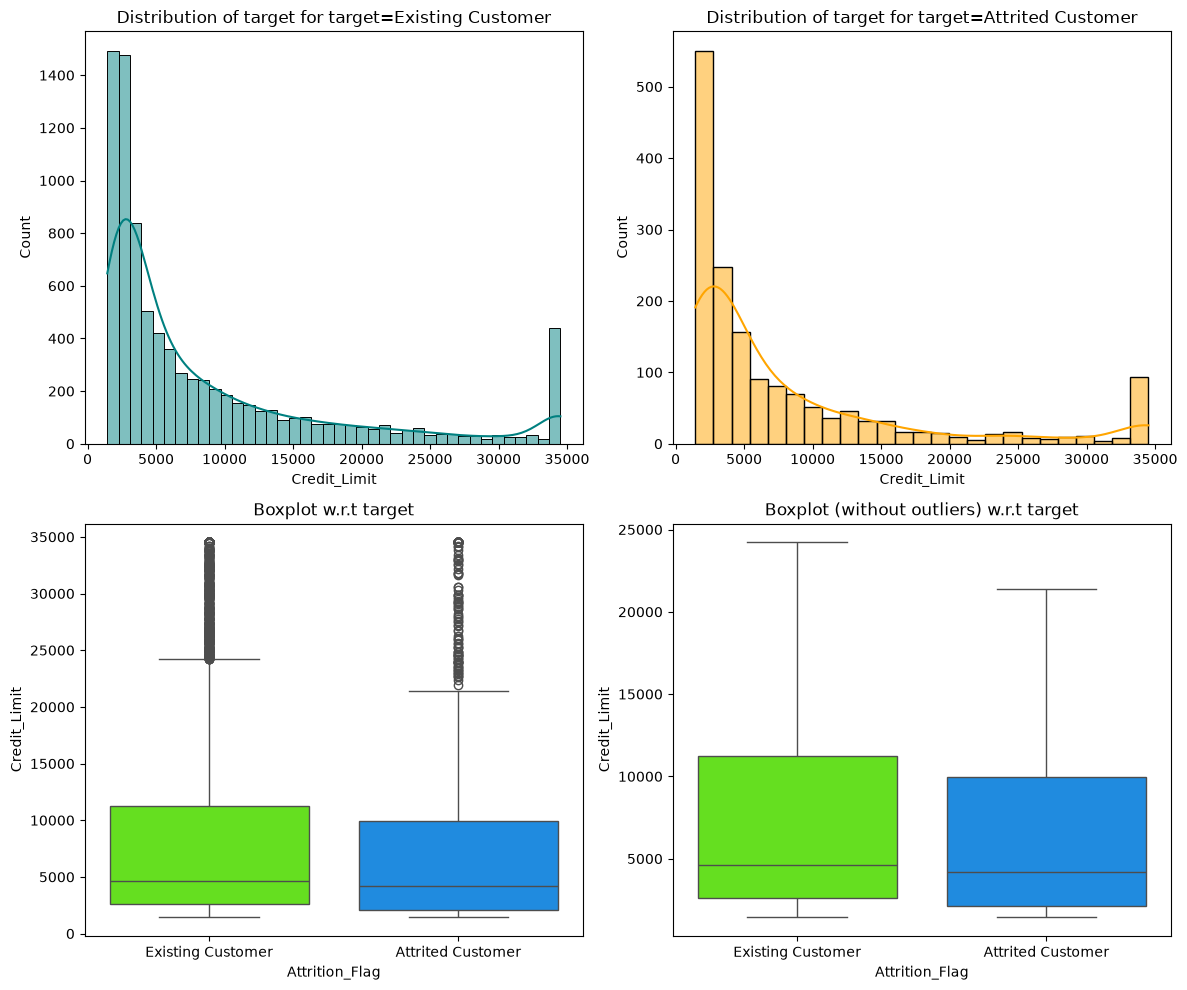

In [45]:
distribution_plot_wrt_target(BankChurners, "Credit_Limit", "Attrition_Flag")

Attrition_Flag vs Customer_Age

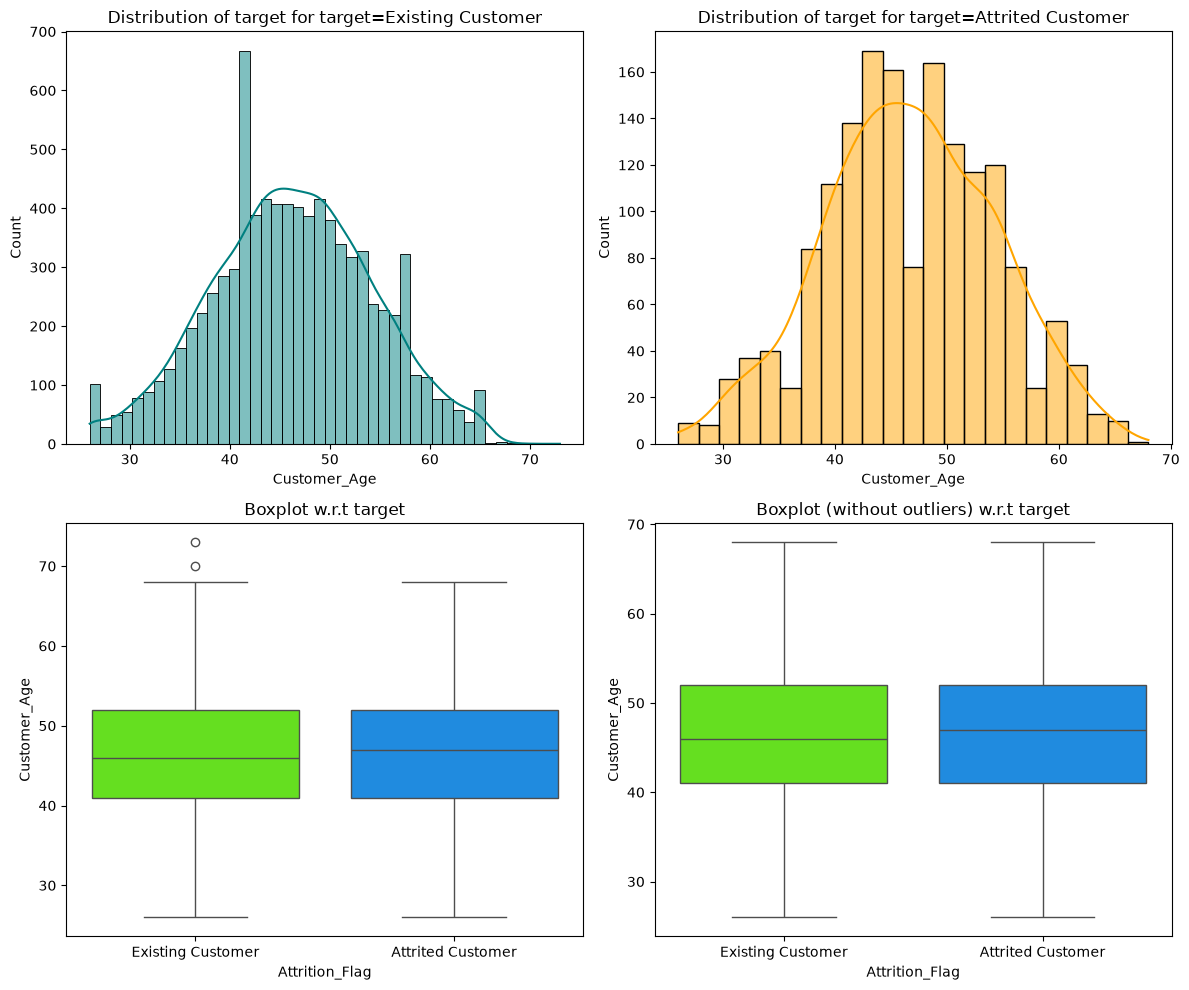

In [46]:
distribution_plot_wrt_target(BankChurners, "Customer_Age", "Attrition_Flag")

Total_Trans_Ct vs Attrition_Flag

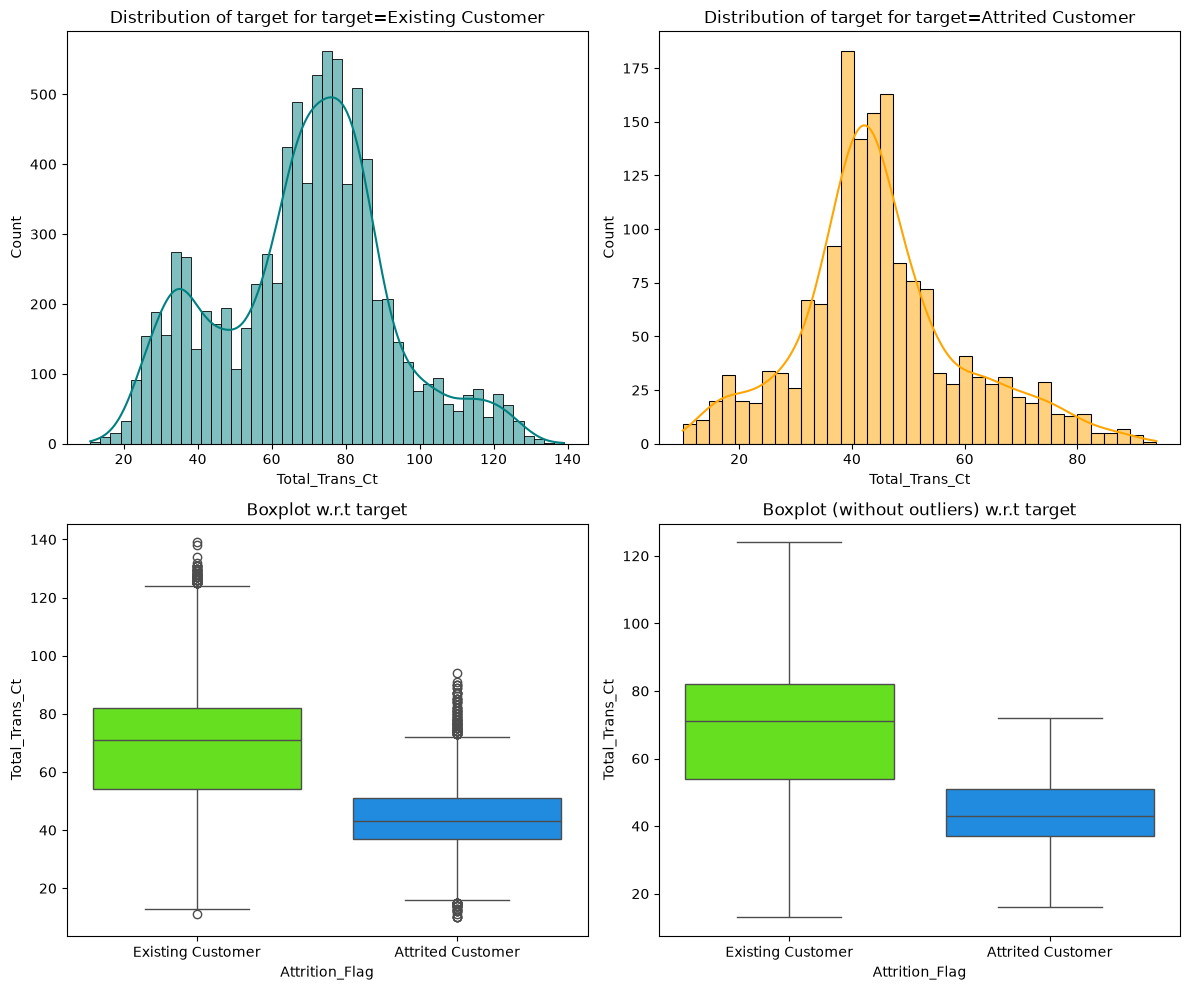

In [47]:
distribution_plot_wrt_target(BankChurners, "Total_Trans_Ct", "Attrition_Flag")

Total_Trans_Amt vs Attrition_Flag

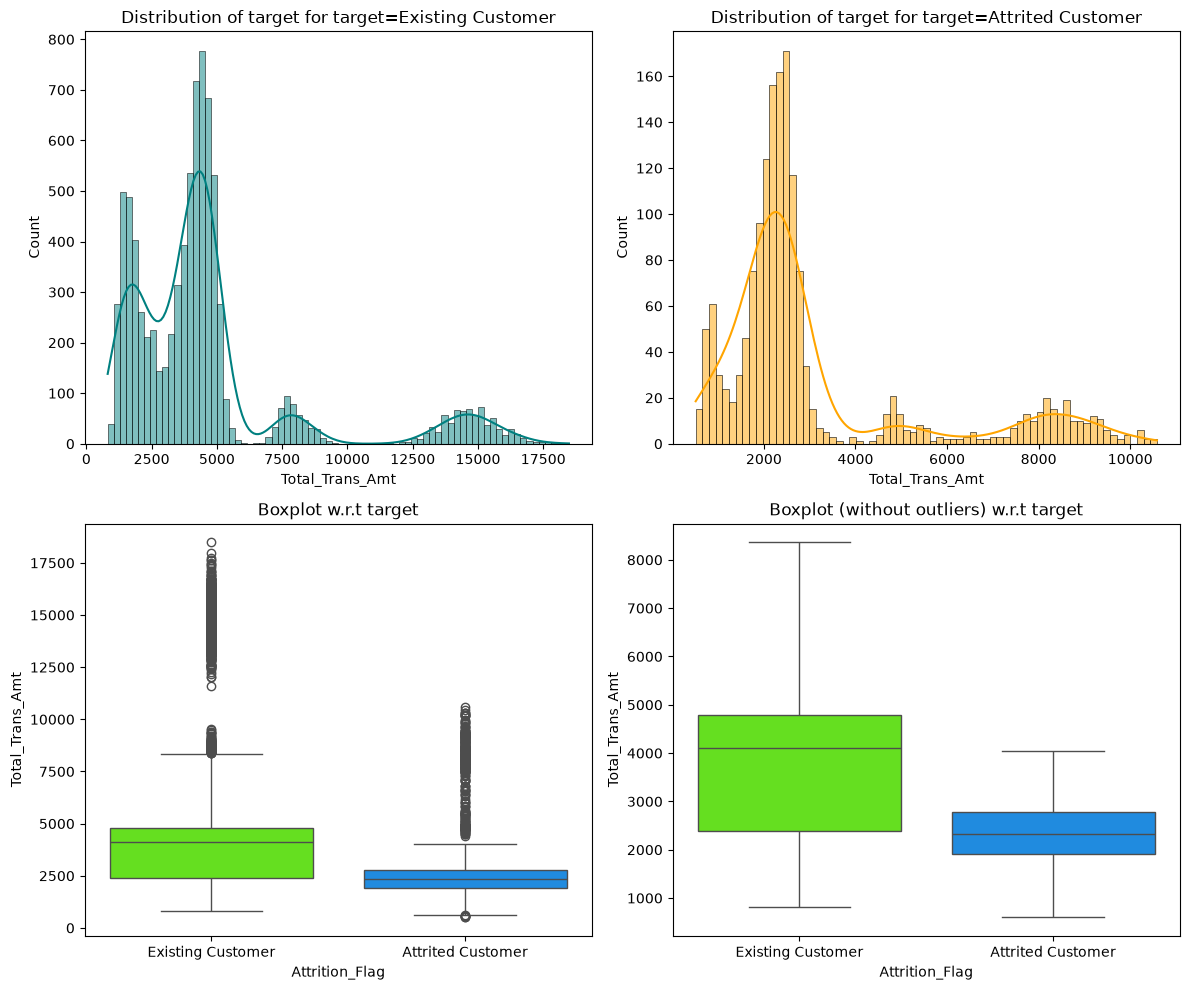

In [48]:
distribution_plot_wrt_target(BankChurners, "Total_Trans_Amt", "Attrition_Flag")


Total_Ct_Chng_Q4_Q1 vs Attrition_Flag

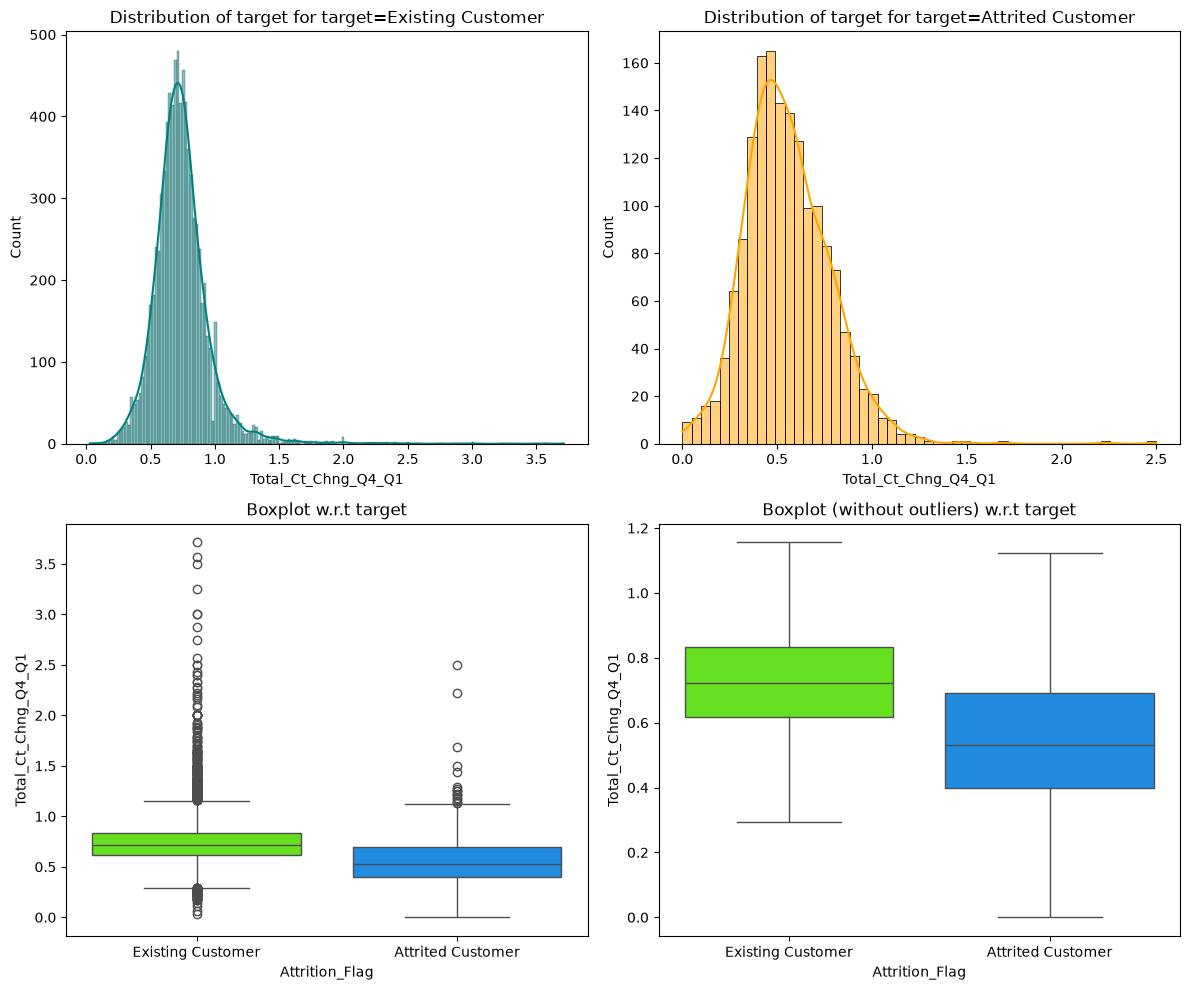

In [49]:
distribution_plot_wrt_target(BankChurners, "Total_Ct_Chng_Q4_Q1", "Attrition_Flag")

Avg_Utilization_Ratio vs Attrition_Flag

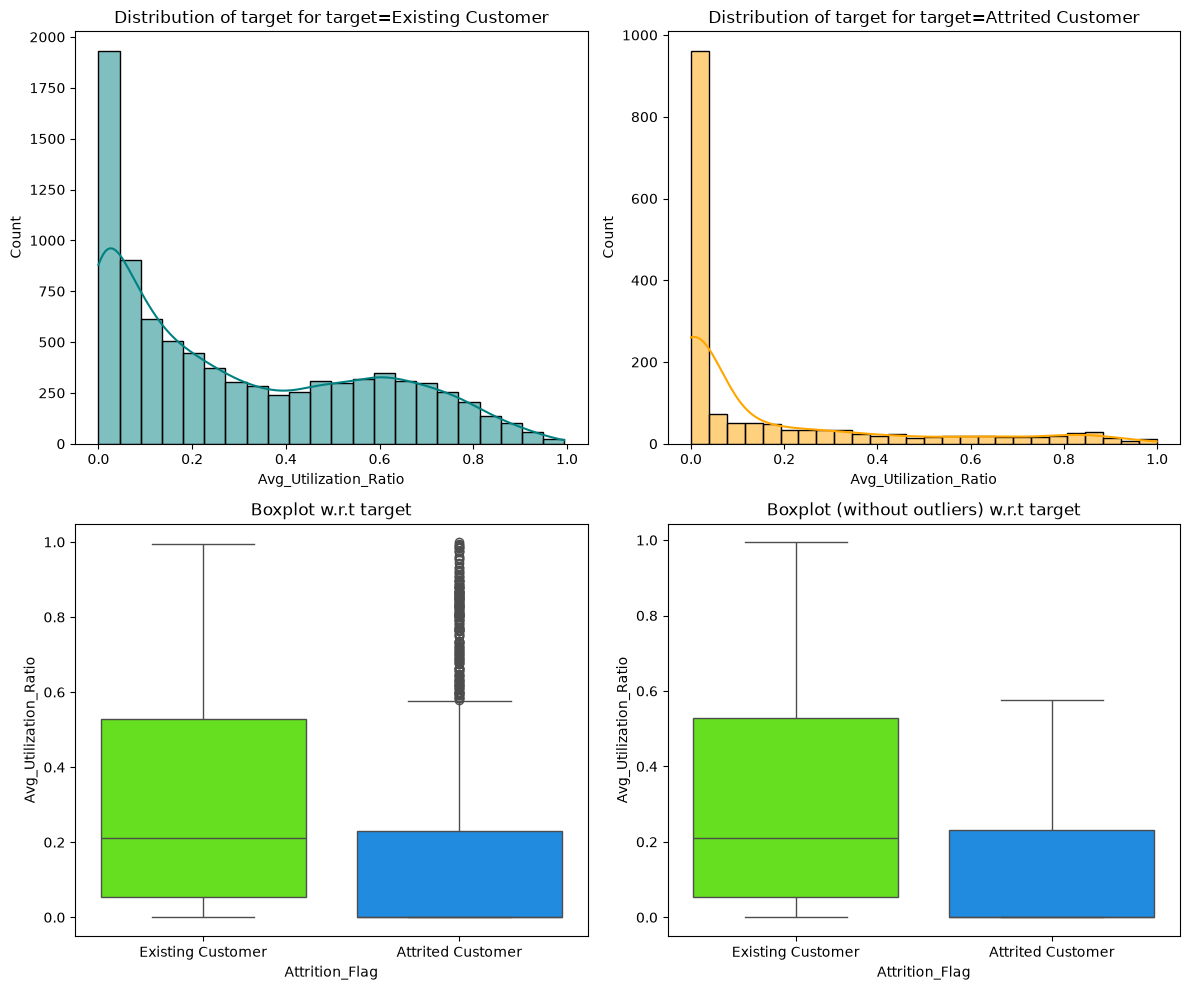

In [50]:
distribution_plot_wrt_target(BankChurners, "Avg_Utilization_Ratio", "Attrition_Flag")

Attrition_Flag vs Months_on_book

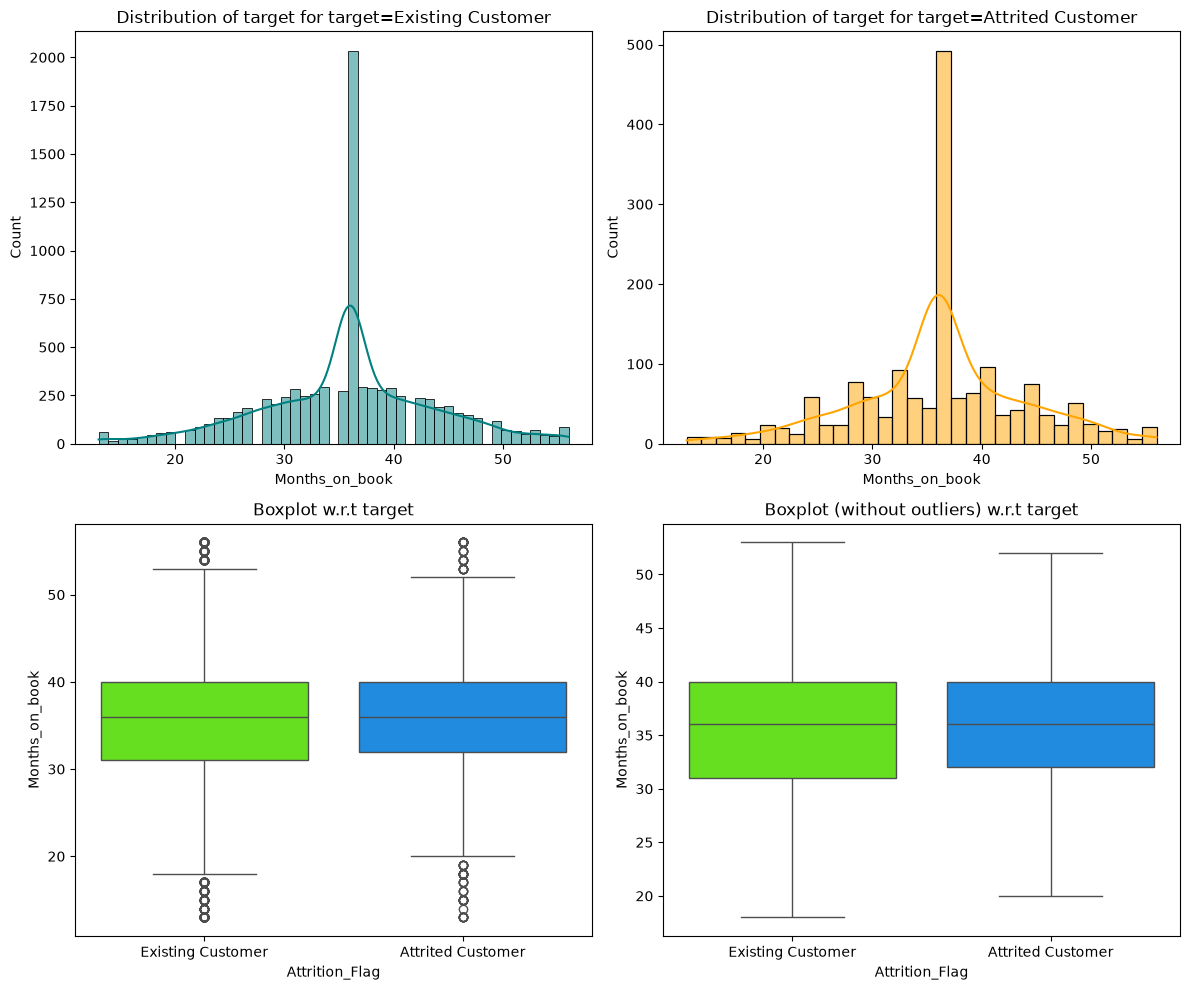

In [51]:
distribution_plot_wrt_target(BankChurners, "Months_on_book", "Attrition_Flag")


Attrition_Flag vs Avg_Open_To_Buy

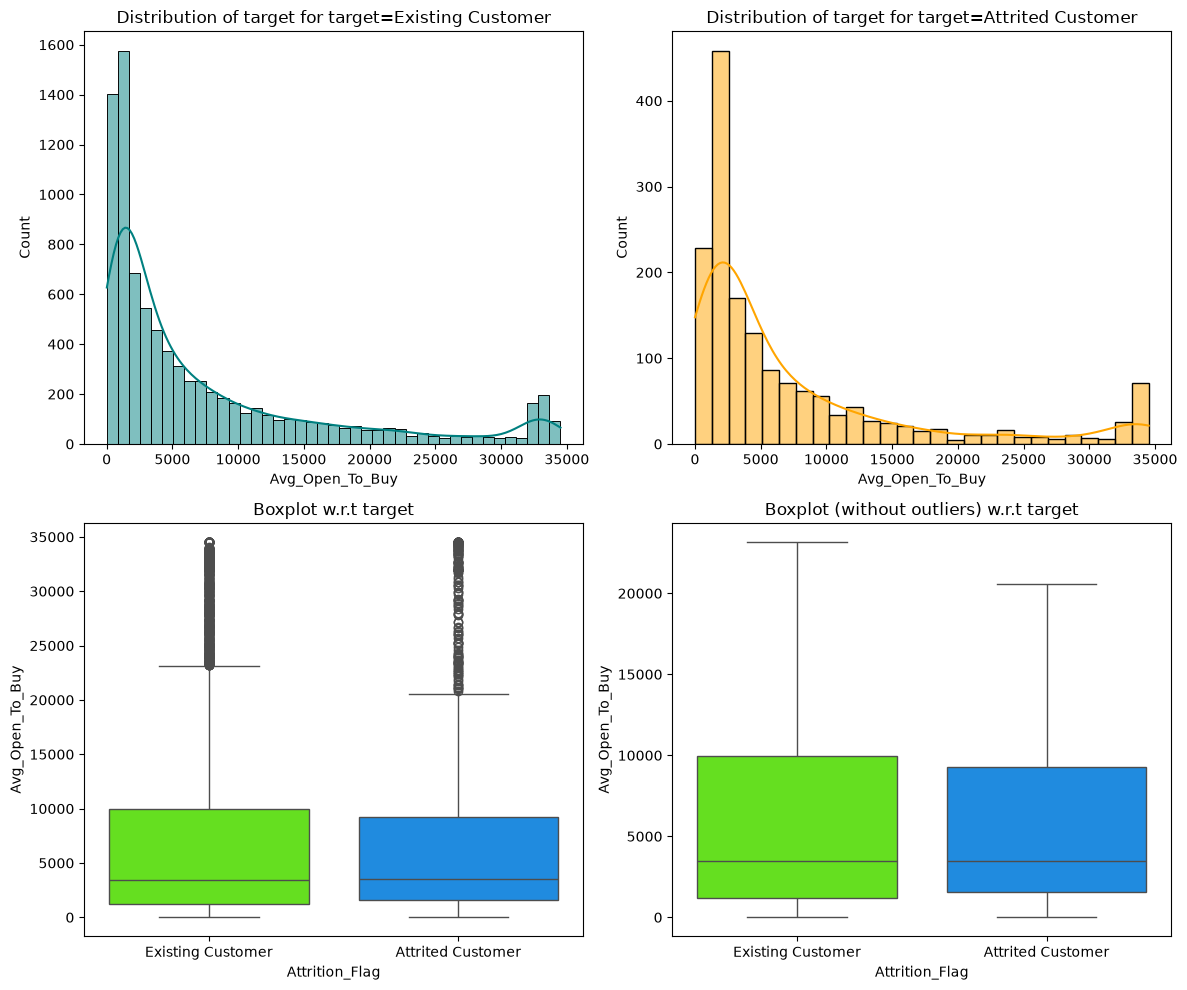

In [52]:
distribution_plot_wrt_target(BankChurners, "Avg_Open_To_Buy", "Attrition_Flag")

### Findings from bivariate analysis
**Strong signals (activity and relationship depth):**
- **Contacts with the bank** rise with churn steadily: 1.8% churn at 0 contacts, 20% at 3, 34% at 5, and **all 54 customers with 6 contacts churned**. Repeated contacts look like complaints or problems.
- **Inactivity:** churn climbs from 4.5% after 1 inactive month to 15% at 2, 22% at 3 and **30% at 4 months**. (The 29 customers with 0 inactive months churned at 52%, too few to read much into.)
- **Products held:** customers with 1 or 2 products churn at 26 to 28%, against 10 to 12% for 4 to 6 products.
- **Transaction count and amount:** churners made a median 43 transactions worth 2,329 in the year, against 71 worth 4,100 for those who stayed.
- **Q4 to Q1 change in transaction count:** lower for churners (median 0.53 against 0.72): their activity was already falling.
- **Revolving balance and utilisation:** the median churner carries **no revolving balance** (0 against 1,364) and so has 0 utilisation. Customers who are not using the card are on the way out.

**Weak or no signal (demographics):**
- **Gender:** women churn slightly more (17.4% against 14.6%).
- **Marital status, education, income and dependents:** churn rates sit within a few points of the 16% average for every group. Doctorate holders (21%) and the $120K+ and under-$40K groups (17%) are only slightly higher, and the $60K to $80K group is lowest (13.5%).
- **Credit limit, age, months on book and open-to-buy** barely differ between the two groups.

##Multivariate analysis using Heatmap

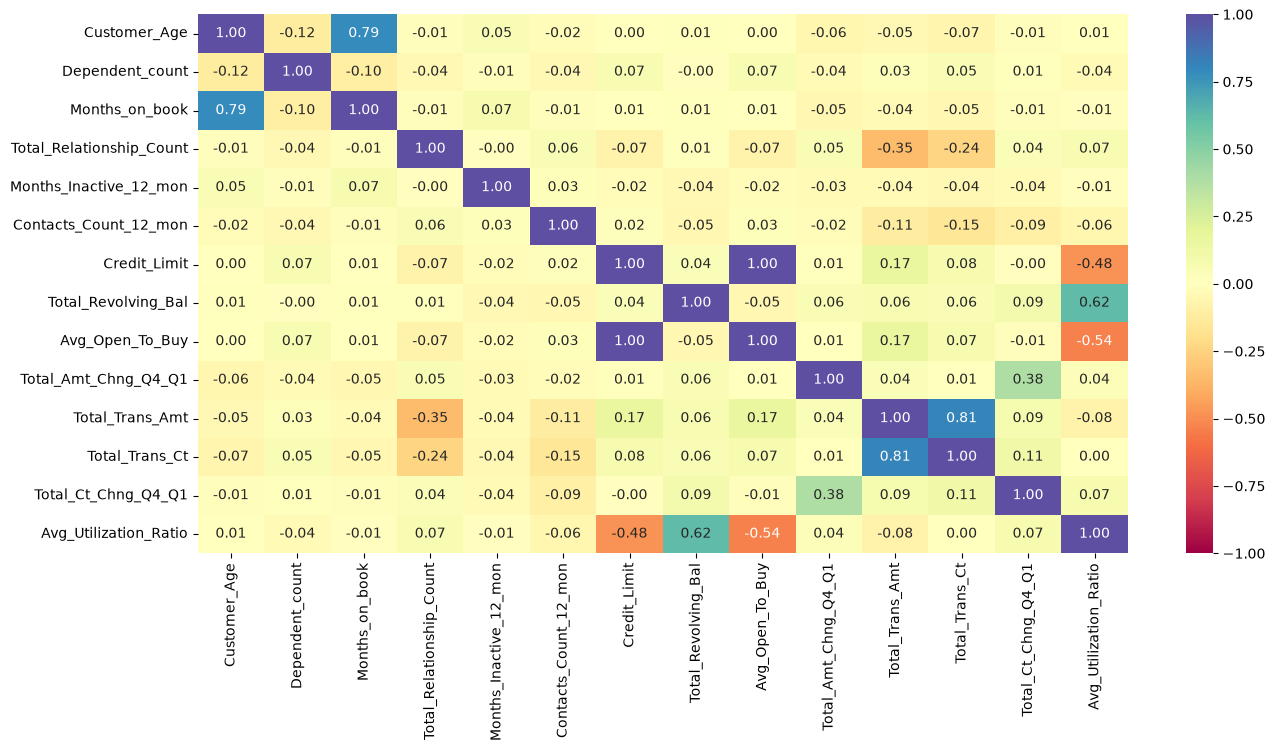

In [53]:
# Correlation between the numerical features (the ID column is excluded)
numerical_data = BankChurners.drop(columns=["CLIENTNUM"]).select_dtypes("number")

plt.figure(figsize=(15, 7))
sns.heatmap(numerical_data.corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

### Findings from the heatmap
- **Credit limit and average open-to-buy** are almost perfectly correlated (1.00): open-to-buy is the limit minus the balance, so it adds little new information.
- **Total transaction amount and count** move together (0.81), and so do **customer age and months on book** (0.79).
- **Revolving balance and utilisation ratio** are positively correlated (0.62); utilisation is negatively correlated with credit limit and open-to-buy.
- **Change in transaction count and change in amount (Q4 to Q1)** are moderately correlated.
- Tree-based models cope well with correlated inputs, so no feature is removed. Correlated features do share importance, which is kept in mind when reading feature importance later.

## Data Pre-processing

### Target, identifier and the anomalous income value
- **Target:** churners (`Attrited Customer`) are the positive class, coded **1**. Every recall and precision figure below is about finding churners.
- `CLIENTNUM` is a customer identifier with no predictive meaning, so it is dropped.
- `Income_Category` holds the placeholder `abc` for 1,112 customers. It is treated as missing.

In [54]:
data = BankChurners.drop(columns=["CLIENTNUM"]).copy()
data["Income_Category"] = data["Income_Category"].replace("abc", np.nan)

y = (data.pop("Attrition_Flag") == "Attrited Customer").astype(int)
X = data

CAT_COLS = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]

print(X.shape)
print(y.value_counts().rename({0: "Existing customer (0)", 1: "Attrited customer (1)"}))
print(f"Churn rate: {y.mean():.1%}")
X.isna().sum()[lambda s: s > 0]

(10127, 19)
Attrition_Flag
Existing customer (0)    8500
Attrited customer (1)    1627
Name: count, dtype: int64
Churn rate: 16.1%


Education_Level    1519
Marital_Status      749
Income_Category    1112
dtype: int64

### Outlier check
- Outliers are kept. They are real customers (high limits, very active spenders), each feature has under 10% of values outside the IQR fences, and the tree-based models used below are not sensitive to extreme values.

In [55]:
Q1 = X[NUM_COLS].quantile(0.25)
Q3 = X[NUM_COLS].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

# Percentage of values outside the IQR fences, per feature
(((X[NUM_COLS] < lower) | (X[NUM_COLS] > upper)).mean() * 100).round(2).sort_values(ascending=False)

Credit_Limit                9.72
Avg_Open_To_Buy             9.51
Total_Trans_Amt             8.85
Contacts_Count_12_mon       6.21
Total_Amt_Chng_Q4_Q1        3.91
Total_Ct_Chng_Q4_Q1         3.89
Months_on_book              3.81
Months_Inactive_12_mon      3.27
Customer_Age                0.02
Total_Trans_Ct              0.02
Total_Relationship_Count    0.00
Dependent_count             0.00
Total_Revolving_Bal         0.00
Avg_Utilization_Ratio       0.00
dtype: float64

### Train-test split
- **80% train, 20% test, stratified**, so both sets keep the 16% churn rate.
- Model comparison, tuning and the choice of decision threshold all use **5-fold stratified cross-validation inside the training set**. With about 1,300 churners in training, five validation folds give a steadier estimate than one small validation set.
- The test set is used **once**, at the very end, to report the final model.

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Churn rate  train: {y_train.mean():.1%}  test: {y_test.mean():.1%}")

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

Train: (8101, 19)  Test: (2026, 19)
Churn rate  train: 16.1%  test: 16.0%


### Missing values and encoding, inside a pipeline
- Missing education, marital status and income become their own **`Unknown`** level rather than the most frequent value. The missing groups churn at about the average rate, and filling them with the mode would quietly inflate the largest group.
- Categories are **one-hot encoded** with `handle_unknown="ignore"`, so a category never seen in training cannot break a prediction.
- Both steps live in a scikit-learn `ColumnTransformer` that is fitted on training folds only. That prevents leakage, and the **same transformation ships with the deployed model**.
- Tree models use the raw numbers; logistic regression gets them standardised.

In [57]:
def make_preprocessor(scale_numeric=False):
    """Impute and one-hot encode the categorical columns; pass through (or scale) the numerical ones."""
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    numeric = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer(
        [("cat", categorical, CAT_COLS), ("num", numeric, NUM_COLS)],
        verbose_feature_names_out=False,
    )


encoded_names = make_preprocessor().fit(X_train).get_feature_names_out()
print(len(encoded_names), "model inputs after encoding")
list(encoded_names)

37 model inputs after encoding


['Gender_F',
 'Gender_M',
 'Education_Level_College',
 'Education_Level_Doctorate',
 'Education_Level_Graduate',
 'Education_Level_High School',
 'Education_Level_Post-Graduate',
 'Education_Level_Uneducated',
 'Education_Level_Unknown',
 'Marital_Status_Divorced',
 'Marital_Status_Married',
 'Marital_Status_Single',
 'Marital_Status_Unknown',
 'Income_Category_$120K +',
 'Income_Category_$40K - $60K',
 'Income_Category_$60K - $80K',
 'Income_Category_$80K - $120K',
 'Income_Category_Less than $40K',
 'Income_Category_Unknown',
 'Card_Category_Blue',
 'Card_Category_Gold',
 'Card_Category_Platinum',
 'Card_Category_Silver',
 'Customer_Age',
 'Dependent_count',
 'Months_on_book',
 'Total_Relationship_Count',
 'Months_Inactive_12_mon',
 'Contacts_Count_12_mon',
 'Credit_Limit',
 'Total_Revolving_Bal',
 'Avg_Open_To_Buy',
 'Total_Amt_Chng_Q4_Q1',
 'Total_Trans_Amt',
 'Total_Trans_Ct',
 'Total_Ct_Chng_Q4_Q1',
 'Avg_Utilization_Ratio']

## Model Building

### Model evaluation criterion
The model's predictions translate as follows:
- **True positive:** a churner the model flags, so the bank can act before they leave.
- **False negative:** a churner the model misses. The bank loses the customer and their fee income.
- **False positive:** a loyal customer flagged by mistake. The cost is a retention call or offer.

A missed churner costs far more than an unnecessary call, so **recall comes first**. Precision still matters: flagging every customer gives a recall of 1.0 and is useless. So:
- **PR-AUC (average precision)** compares and tunes the models. It scores how well a model *ranks* customers by risk, independent of any threshold, and suits imbalanced data better than ROC-AUC or accuracy.
- **F2** (recall weighted twice as much as precision) picks the decision threshold.
- **Recall, precision and the confusion matrix** report the final model.

**Helper functions** for the metrics and the confusion matrix, at any decision threshold:

In [58]:
def model_performance_classification_sklearn(model, predictors, target, threshold=0.5):
    """Accuracy, recall, precision, F1, F2, PR-AUC and ROC-AUC at the given threshold."""
    proba = model.predict_proba(predictors)[:, 1]
    pred = (proba >= threshold).astype(int)
    return pd.DataFrame(
        {
            "Accuracy": accuracy_score(target, pred),
            "Recall": recall_score(target, pred),
            "Precision": precision_score(target, pred),
            "F1": f1_score(target, pred),
            "F2": fbeta_score(target, pred, beta=2),
            "PR-AUC": average_precision_score(target, proba),
            "ROC-AUC": roc_auc_score(target, proba),
        },
        index=[0],
    )


def confusion_matrix_sklearn(model, predictors, target, threshold=0.5, title=None):
    """Confusion matrix with counts and percentages at the given threshold."""
    pred = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    cm = confusion_matrix(target, pred)
    labels = np.asarray([f"{v:.0f}\n{v / cm.sum():.2%}" for v in cm.flatten()]).reshape(2, 2)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False,
                xticklabels=["Existing", "Attrited"], yticklabels=["Existing", "Attrited"])
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    if title:
        plt.title(title)
    plt.show()

### Approach
1. Seven classifiers (logistic regression, decision tree, bagging, random forest, AdaBoost, gradient boosting and XGBoost), each trained on **original data**, **SMOTE-oversampled data** and **randomly undersampled data**, plus **class weights** for the models that support them: 25 candidates.
2. Resampling happens **inside each cross-validation fold** through an `imblearn` pipeline, so synthetic or discarded rows never touch the fold used for scoring.
3. All candidates get the same 5-fold cross-validation. The three strongest algorithms are tuned.
4. The best tuned model gets a decision threshold chosen from out-of-fold predictions, then a single evaluation on the test set.

In [59]:
SPW = (y_train == 0).sum() / (y_train == 1).sum()  # XGBoost class weight: existing / attrited


def base_models(weighted=False):
    cw = "balanced" if weighted else None
    return {
        "Logistic regression": LogisticRegression(max_iter=2000, class_weight=cw),
        "Decision tree": DecisionTreeClassifier(random_state=1, class_weight=cw),
        "Bagging": BaggingClassifier(random_state=1, n_jobs=2),
        "Random forest": RandomForestClassifier(random_state=1, n_jobs=2, class_weight=cw),
        "AdaBoost": AdaBoostClassifier(random_state=1),
        "Gradient boosting": GradientBoostingClassifier(random_state=1),
        "XGBoost": XGBClassifier(random_state=1, n_jobs=2, eval_metric="logloss",
                                 scale_pos_weight=SPW if weighted else 1),
    }


WEIGHTABLE = ["Logistic regression", "Decision tree", "Random forest", "XGBoost"]
SAMPLERS = {
    "Original": None,
    "SMOTE oversampled": SMOTE(random_state=1),
    "Undersampled": RandomUnderSampler(random_state=1),
}
SCORING = {
    "Recall": "recall",
    "Precision": "precision",
    "F2": make_scorer(fbeta_score, beta=2),
    "PR-AUC": "average_precision",
}


def build(model, sampler=None):
    """Pre-processing (+ optional resampling) + model. Plain scikit-learn Pipeline when no resampling."""
    prep = ("prep", make_preprocessor(scale_numeric=isinstance(model, LogisticRegression)))
    if sampler is None:
        return Pipeline([prep, ("model", model)])
    return ImbPipeline([prep, ("sample", sampler), ("model", model)])


def cv_scores(pipeline):
    s = cross_validate(pipeline, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=5)
    return {k: s[f"test_{k}"].mean() for k in SCORING}

### Building 25 candidate models

In [60]:
%%time
rows = []
for data_name, sampler in SAMPLERS.items():
    for name, model in base_models().items():
        rows.append({"Model": name, "Training data": data_name, **cv_scores(build(model, sampler))})

for name, model in base_models(weighted=True).items():
    if name in WEIGHTABLE:
        rows.append({"Model": name, "Training data": "Class weights", **cv_scores(build(model))})

results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
results.style.format(precision=3).background_gradient(subset=list(SCORING), cmap="Greens")

CPU times: total: 1.33 s
Wall time: 35.9 s


,Model,Training data,Recall,Precision,F2,PR-AUC
0,XGBoost,SMOTE oversampled,0.901,0.924,0.905,0.969
1,XGBoost,Class weights,0.924,0.907,0.921,0.968
2,XGBoost,Original,0.889,0.936,0.898,0.967
3,XGBoost,Undersampled,0.953,0.787,0.914,0.956
4,Gradient boosting,Original,0.842,0.931,0.858,0.954
5,Gradient boosting,SMOTE oversampled,0.882,0.886,0.883,0.953
6,Gradient boosting,Undersampled,0.955,0.762,0.909,0.948
7,Random forest,Class weights,0.730,0.927,0.762,0.940
8,Random forest,Original,0.774,0.924,0.800,0.938
9,Random forest,SMOTE oversampled,0.820,0.891,0.833,0.926


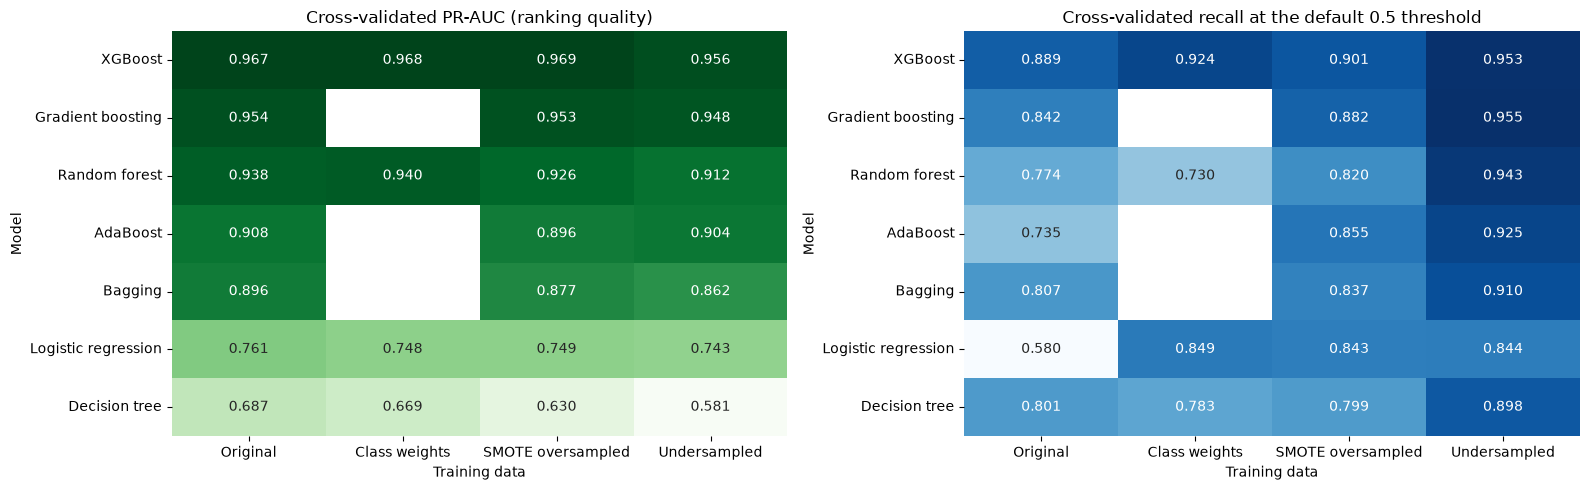

In [61]:
order = results.groupby("Model")["PR-AUC"].max().sort_values(ascending=False).index
pivot = results.pivot(index="Model", columns="Training data", values="PR-AUC").loc[order]
pivot = pivot[["Original", "Class weights", "SMOTE oversampled", "Undersampled"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Greens", ax=axes[0], cbar=False)
axes[0].set_title("Cross-validated PR-AUC (ranking quality)")
recall_pivot = results.pivot(index="Model", columns="Training data", values="Recall").loc[order, pivot.columns]
sns.heatmap(recall_pivot, annot=True, fmt=".3f", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("Cross-validated recall at the default 0.5 threshold")
plt.tight_layout()
plt.show()

### Performance analysis of the 25 models
- **Boosting leads.** XGBoost has the best PR-AUC under every training-data option (0.956 to 0.969), followed by gradient boosting (0.948 to 0.954) and random forest (0.912 to 0.940). Logistic regression (about 0.75) and a single decision tree (0.58 to 0.69) are far behind: the churn pattern is non-linear.
- **Resampling does not improve the ranking.** For XGBoost, original data, SMOTE and class weights land within 0.002 PR-AUC of each other, and undersampling is worse (0.956), because it throws away 80% of the loyal customers.
- **What resampling does change is the threshold.** Undersampled XGBoost has the highest recall at 0.5 (0.953) but the lowest precision (0.787). That is the same trade-off a lower threshold gives on the original data, without discarding data or distorting the probabilities.
- **Selected for tuning:** XGBoost, gradient boosting and random forest, the three strongest algorithms, tuned on the original data.

### Hyperparameter tuning

- The three strongest algorithms are tuned on the **original data** with `RandomizedSearchCV` (40 combinations each, 5-fold, optimising PR-AUC).
- Class imbalance is then handled by the **decision threshold** instead of resampling. The comparison above shows why: resampling and class weights raise recall at 0.5 only by trading away precision, without ranking customers any better. Moving the threshold achieves the same trade-off and keeps the predicted probabilities honest, which the app needs to show a meaningful risk score.

In [62]:
PARAM_GRIDS = {
    "XGBoost": (
        XGBClassifier(random_state=1, n_jobs=2, eval_metric="logloss"),
        {
            "model__n_estimators": [200, 400, 600, 800, 1000],
            "model__learning_rate": [0.02, 0.03, 0.05, 0.1],
            "model__max_depth": [3, 4, 5, 6],
            "model__min_child_weight": [1, 2, 4],
            "model__subsample": [0.7, 0.8, 0.9],
            "model__colsample_bytree": [0.5, 0.7, 0.9],
            "model__gamma": [0, 0.5, 1],
            "model__reg_lambda": [1, 3, 10],
        },
    ),
    "Gradient boosting": (
        GradientBoostingClassifier(random_state=1),
        {
            "model__n_estimators": [100, 200, 300, 500],
            "model__learning_rate": [0.05, 0.1, 0.2],
            "model__max_depth": [2, 3, 4, 5],
            "model__subsample": [0.7, 0.8, 1.0],
            "model__max_features": [0.5, 0.7, None],
            "model__min_samples_leaf": [1, 5, 10],
        },
    ),
    "Random forest": (
        RandomForestClassifier(random_state=1, n_jobs=2),
        {
            "model__n_estimators": [300, 500, 800],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.3, 0.5],
            "model__class_weight": [None, "balanced_subsample"],
        },
    ),
}

searches = {}
for name, (model, grid) in PARAM_GRIDS.items():
    start = time.time()
    search = RandomizedSearchCV(build(model), grid, n_iter=40, scoring=SCORING, refit="PR-AUC",
                                cv=CV, random_state=1, n_jobs=8)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name}: PR-AUC {search.best_score_:.4f} in {time.time() - start:.0f}s")
    print("   ", {k.replace("model__", ""): v for k, v in search.best_params_.items()})

XGBoost: PR-AUC 0.9718 in 99s
    {'subsample': 0.9, 'reg_lambda': 3, 'n_estimators': 1000, 'min_child_weight': 2, 'max_depth': 6, 'learning_rate': 0.03, 'gamma': 0, 'colsample_bytree': 0.5}


Gradient boosting: PR-AUC 0.9720 in 190s
    {'subsample': 0.8, 'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 4, 'learning_rate': 0.2}


Random forest: PR-AUC 0.9524 in 337s
    {'n_estimators': 800, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None, 'class_weight': None}


### Model Comparison and Final Model Selection

In [63]:
tuned = pd.DataFrame(
    {
        name: {k: s.cv_results_[f"mean_test_{k}"][s.best_index_] for k in SCORING}
        for name, s in searches.items()
    }
).T.sort_values("PR-AUC", ascending=False)
tuned.index.name = "Tuned model (5-fold CV, threshold 0.5)"
tuned.style.format(precision=4).highlight_max(color="#c6efce")

,Recall,Precision,F2,PR-AUC
"Tuned model (5-fold CV, threshold 0.5)",,,,
Gradient boosting,0.8879,0.9407,0.8979,0.9720
XGBoost,0.8909,0.9348,0.8994,0.9718
Random forest,0.8379,0.9317,0.8551,0.9524


### Final model selection
- XGBoost (0.9718) and gradient boosting (0.9720) are **tied on PR-AUC**: the gap of 0.0002 is far smaller than the fold-to-fold variation. Random forest trails at 0.952.
- The tie is broken on **calibration**, because the app shows each customer's probability and the bank plans call volumes from it. XGBoost's out-of-fold predictions have the lower Brier score (0.0206 against 0.0221) and a clearly lower log loss (0.073 against 0.096). Tuned gradient boosting (learning rate 0.2, 500 trees) pushes probabilities towards 0 and 1, so it is confidently wrong more often.
- **XGBoost is the final model.** It is also faster to train and gives exact SHAP explanations natively.

In [64]:
# Out-of-fold predictions for the two best tuned models: every training customer is scored by a model that never saw them
finalists = tuned.index[:2]
oof = {}
rows = []
for name in finalists:
    est = searches[name].best_estimator_
    oof[name] = cross_val_predict(est, X_train, y_train, cv=CV, method="predict_proba", n_jobs=5)[:, 1]
    rows.append({
        "Model": name,
        "CV PR-AUC": tuned.loc[name, "PR-AUC"],
        "Training PR-AUC": average_precision_score(y_train, est.predict_proba(X_train)[:, 1]),
        "OOF Brier score": brier_score_loss(y_train, oof[name]),
        "OOF log loss": log_loss(y_train, oof[name]),
    })
finalists_df = pd.DataFrame(rows).set_index("Model")

# Rule: higher PR-AUC wins, unless the two are within 0.002 (a tie); then the better-calibrated model (lower log loss) wins
gap = finalists_df["CV PR-AUC"].iloc[0] - finalists_df["CV PR-AUC"].iloc[1]
best_name = finalists_df.index[0] if gap >= 0.002 else finalists_df["OOF log loss"].idxmin()
final_model = searches[best_name].best_estimator_
print(f"PR-AUC gap {gap:.4f} -> final model: {best_name}")
finalists_df.round(4)

PR-AUC gap 0.0002 -> final model: XGBoost


,CV PR-AUC,Training PR-AUC,OOF Brier score,OOF log loss
Model,,,,
Gradient boosting,0.9720,1.0,0.0221,0.0961
XGBoost,0.9718,1.0,0.0206,0.0726


### Choosing the decision threshold
- Out-of-fold probabilities on the training set (each customer scored by a model that never saw them) show how recall and precision trade off as the threshold moves.
- The threshold with the **highest F2** is used.

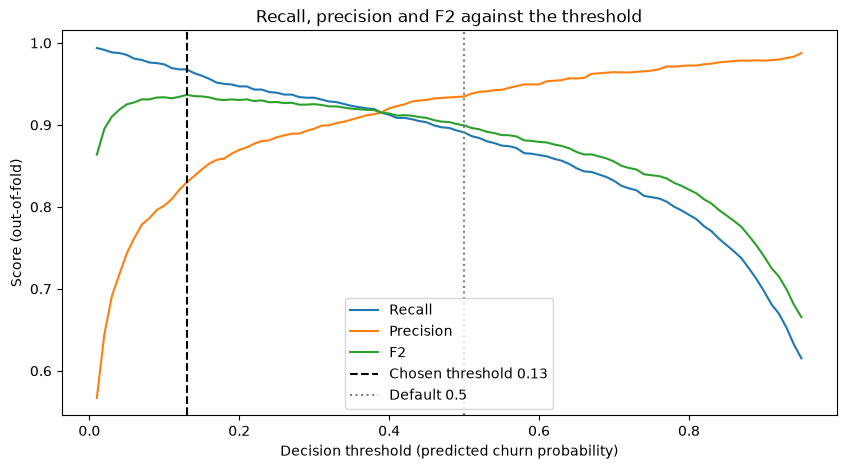

,Recall,Precision,F2
Threshold,,,
0.50,0.891,0.935,0.899
0.13,0.968,0.830,0.937


In [65]:
oof_proba = oof[best_name]

thresholds = np.round(np.arange(0.01, 0.951, 0.01), 2)
curve = pd.DataFrame(
    {
        "Threshold": thresholds,
        "Recall": [recall_score(y_train, oof_proba >= t) for t in thresholds],
        "Precision": [precision_score(y_train, oof_proba >= t) for t in thresholds],
        "F2": [fbeta_score(y_train, oof_proba >= t, beta=2) for t in thresholds],
    }
)
THRESHOLD = float(curve.loc[curve["F2"].idxmax(), "Threshold"])

plt.figure(figsize=(10, 5))
for col, colour in [("Recall", "tab:blue"), ("Precision", "tab:orange"), ("F2", "tab:green")]:
    plt.plot(curve["Threshold"], curve[col], label=col, color=colour)
plt.axvline(THRESHOLD, color="black", linestyle="--", label=f"Chosen threshold {THRESHOLD:.2f}")
plt.axvline(0.5, color="grey", linestyle=":", label="Default 0.5")
plt.xlabel("Decision threshold (predicted churn probability)")
plt.ylabel("Score (out-of-fold)")
plt.title("Recall, precision and F2 against the threshold")
plt.legend()
plt.show()

curve.set_index("Threshold").loc[[0.5, THRESHOLD]].round(3)

### Are the probabilities trustworthy?
The app shows each customer's churn probability, so it should mean what it says: of customers scored around 30%, about 30% should churn. The calibration curve checks this on the out-of-fold predictions.

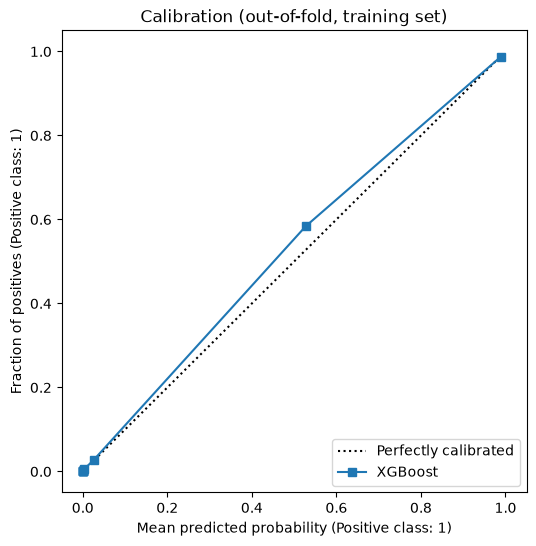

Brier score: 0.0206  (0 is perfect; always predicting 16% scores 0.1349)


In [66]:
fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(y_train, oof_proba, n_bins=10, strategy="quantile", ax=ax, name=best_name)
ax.set_title("Calibration (out-of-fold, training set)")
plt.show()
print(f"Brier score: {brier_score_loss(y_train, oof_proba):.4f}  (0 is perfect; always predicting 16% scores {brier_score_loss(y_train, np.full(len(y_train), y_train.mean())):.4f})")

## Test set final performance

The final model was fitted on the full training set by the search. It now scores the 2,026 test customers it has never seen, once.

In [67]:
train_perf = model_performance_classification_sklearn(final_model, X_train, y_train, THRESHOLD)
test_perf = model_performance_classification_sklearn(final_model, X_test, y_test, THRESHOLD)
test_perf_05 = model_performance_classification_sklearn(final_model, X_test, y_test, 0.5)

comparison = pd.concat([train_perf, test_perf, test_perf_05])
comparison.index = [f"Train (threshold {THRESHOLD:.2f})", f"Test (threshold {THRESHOLD:.2f})", "Test (threshold 0.50)"]
comparison.round(4)

,Accuracy,Recall,Precision,F1,F2,PR-AUC,ROC-AUC
Train (threshold 0.13),0.9896,1.0000,0.9394,0.9688,0.9873,1.0000,1.000
Test (threshold 0.13),0.9615,0.9415,0.8384,0.8870,0.9189,0.9683,0.993
Test (threshold 0.50),0.9738,0.8738,0.9595,0.9147,0.8897,0.9683,0.993


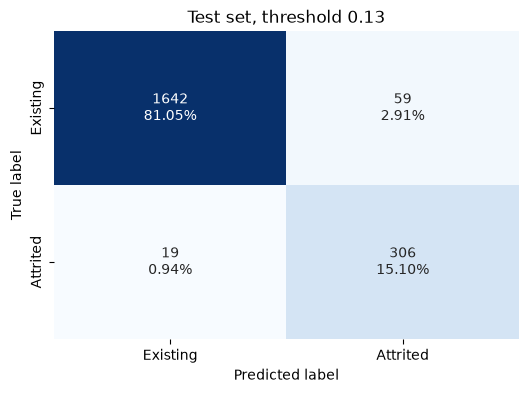

In [68]:
confusion_matrix_sklearn(final_model, X_test, y_test, THRESHOLD, title=f"Test set, threshold {THRESHOLD:.2f}")

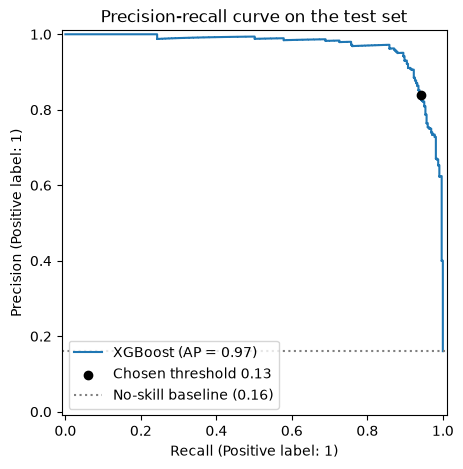

In [69]:
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_estimator(final_model, X_test, y_test, ax=ax, name=best_name)
test_proba = final_model.predict_proba(X_test)[:, 1]
ax.scatter(recall_score(y_test, test_proba >= THRESHOLD), precision_score(y_test, test_proba >= THRESHOLD),
           color="black", zorder=3, label=f"Chosen threshold {THRESHOLD:.2f}")
ax.axhline(y_test.mean(), color="grey", linestyle=":", label=f"No-skill baseline ({y_test.mean():.2f})")
ax.set_title("Precision-recall curve on the test set")
ax.legend(loc="lower left")
plt.show()

### Test set findings
- On 2,026 customers it never saw, the model **catches 306 of the 325 churners (94.2% recall)**, and **84% of the customers it flags really churn** (59 false alarms; 1,642 loyal customers correctly left alone). Only 19 churners are missed.
- PR-AUC is **0.968** (a random ranking would score 0.16) and ROC-AUC 0.993.
- The test results match cross-validation (out-of-fold recall 0.968 and precision 0.830 at the same threshold), so the model generalises. The near-perfect training scores are expected for boosted trees and are not used to judge the model.
- At the default threshold of 0.5 precision would rise to 96% but recall would fall to 87%: 23 more churners missed to save 47 calls. The lower 0.13 threshold reflects the cost asymmetry: a retention call is cheap, a lost card is not.

## What drives the predictions
Feature importance uses **SHAP values**, computed natively by XGBoost (`pred_contribs=True`). For each customer, each feature gets a contribution that pushes the churn score up or down; the contributions add up to the prediction. One-hot columns are summed back into their original feature.

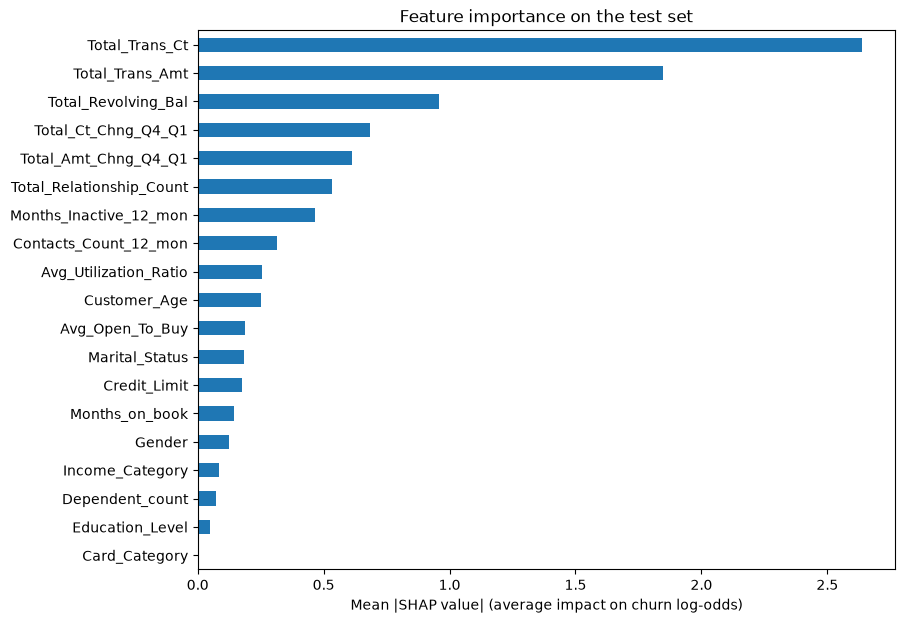

In [70]:
prep = final_model.named_steps["prep"]
booster = final_model.named_steps["model"].get_booster()
encoded_test = prep.transform(X_test)
names = prep.get_feature_names_out()

# SHAP contributions (log-odds); the last column is the bias term
contribs = booster.predict(xgb.DMatrix(encoded_test), pred_contribs=True)[:, :-1]
source = [next((c for c in CAT_COLS if n.startswith(c + "_")), n) for n in names]
shap_values = pd.DataFrame(contribs, columns=names, index=X_test.index).T.groupby(source).sum().T

importance = shap_values.abs().mean().sort_values()
plt.figure(figsize=(9, 7))
importance.plot.barh(color="tab:blue")
plt.xlabel("Mean |SHAP value| (average impact on churn log-odds)")
plt.title("Feature importance on the test set")
plt.show()

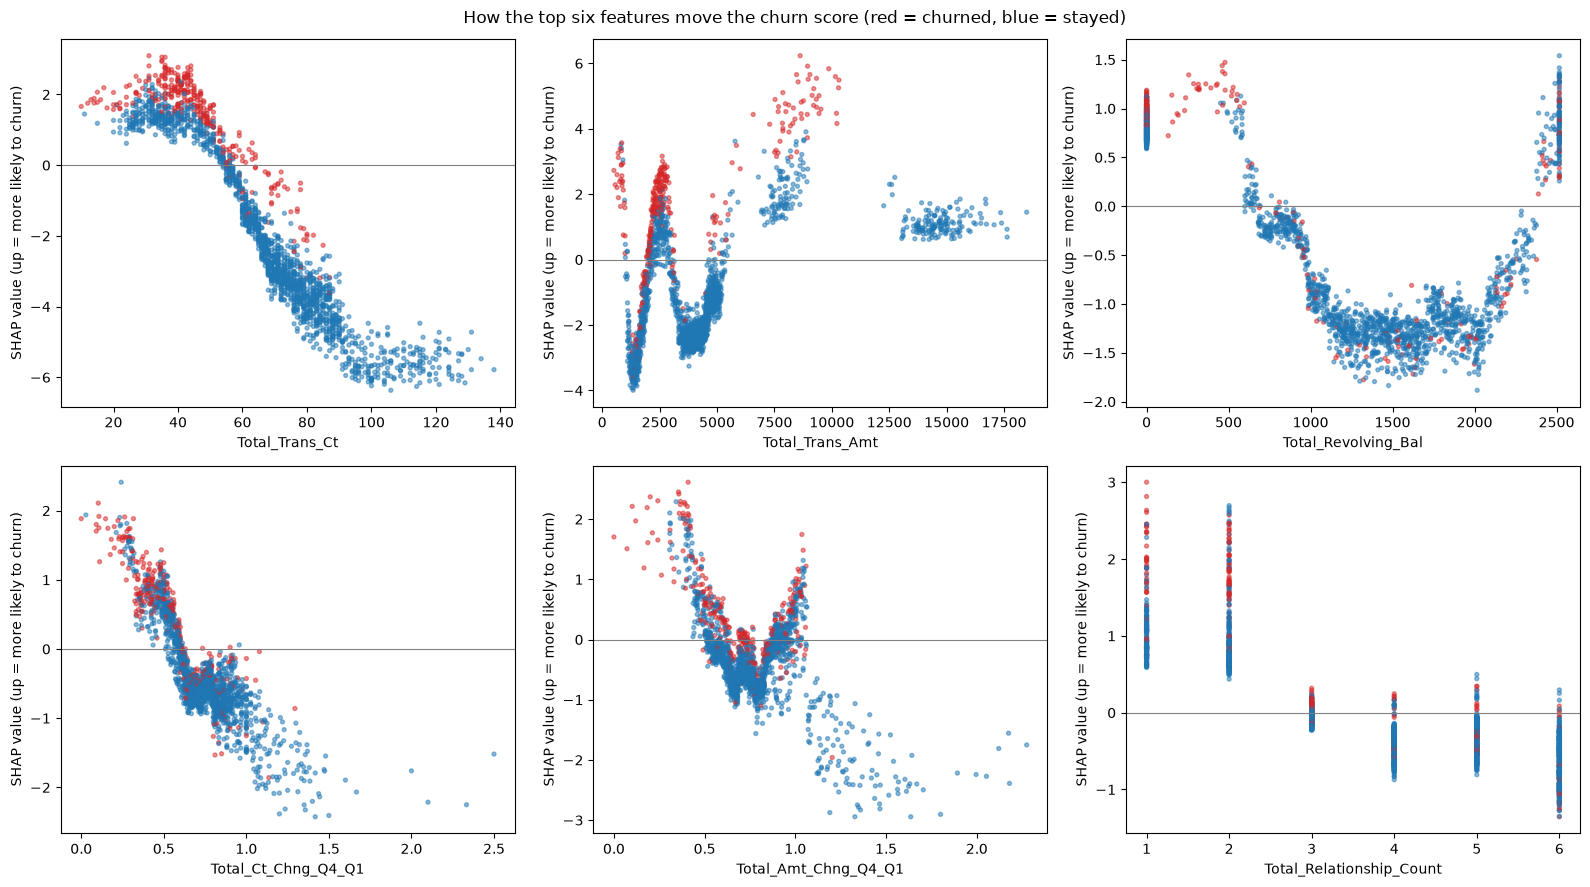

In [71]:
top = importance.sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, top):
    ax.scatter(X_test[feature], shap_values[feature], s=8, alpha=0.5, c=y_test.map({0: "tab:blue", 1: "tab:red"}))
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel(feature)
    ax.set_ylabel("SHAP value (up = more likely to churn)")
fig.suptitle("How the top six features move the churn score (red = churned, blue = stayed)")
plt.tight_layout()
plt.show()

### Findings from the SHAP analysis
- **Transaction count is the strongest driver by far**, then **transaction amount**: customers who use the card less are the ones leaving. Below about 55 transactions a year the contribution turns positive; above 70 it strongly lowers the risk.
- **Revolving balance** comes next: a balance of zero or under 500 (the card is not the customer's main credit line) raises the risk; a balance of 1,000 to 2,000 lowers it.
- **Q4 to Q1 change in transaction count and amount:** a drop in activity raises the risk, an early warning sign.
- **Products held, inactive months and contacts with the bank** follow: one or two products, more inactive months and more contacts all raise the risk.
- **Demographics barely matter.** Income, education, card type and dependents have the smallest contributions, so the model judges customers on behaviour rather than on who they are.

## Saving the model
The whole pipeline (imputation, encoding and the tuned XGBoost model) is saved as one file with `joblib`, with a metadata file holding the threshold, test metrics and library versions. The app loads exactly this pipeline, so a raw customer record goes in and a probability comes out.

In [72]:
import sklearn

MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(final_model, MODEL_DIR / "bank_churn_xgb.joblib")

metadata = {
    "model": best_name,
    "threshold": THRESHOLD,
    "features": {"categorical": CAT_COLS, "numerical": NUM_COLS},
    "params": {k.replace("model__", ""): v for k, v in searches[best_name].best_params_.items()},
    "cv_pr_auc": float(searches[best_name].best_score_),
    "test": {k: round(float(v), 4) for k, v in test_perf.iloc[0].items()},
    "test_rows": int(len(y_test)),
    "train_rows": int(len(y_train)),
    "churn_rate": round(float(y.mean()), 4),
    "versions": {"scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

# Round trip: the saved file must give exactly the same predictions
reloaded = joblib.load(MODEL_DIR / "bank_churn_xgb.joblib")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], test_proba)
print(json.dumps(metadata, indent=2, default=str))

{
  "model": "XGBoost",
  "threshold": 0.13,
  "features": {
    "categorical": [
      "Gender",
      "Education_Level",
      "Marital_Status",
      "Income_Category",
      "Card_Category"
    ],
    "numerical": [
      "Customer_Age",
      "Dependent_count",
      "Months_on_book",
      "Total_Relationship_Count",
      "Months_Inactive_12_mon",
      "Contacts_Count_12_mon",
      "Credit_Limit",
      "Total_Revolving_Bal",
      "Avg_Open_To_Buy",
      "Total_Amt_Chng_Q4_Q1",
      "Total_Trans_Amt",
      "Total_Trans_Ct",
      "Total_Ct_Chng_Q4_Q1",
      "Avg_Utilization_Ratio"
    ]
  },
  "params": {
    "subsample": 0.9,
    "reg_lambda": 3,
    "n_estimators": 1000,
    "min_child_weight": 2,
    "max_depth": 6,
    "learning_rate": 0.03,
    "gamma": 0,
    "colsample_bytree": 0.5
  },
  "cv_pr_auc": 0.9717922574374726,
  "test": {
    "Accuracy": 0.9615,
    "Recall": 0.9415,
    "Precision": 0.8384,
    "F1": 0.887,
    "F2": 0.9189,
    "PR-AUC": 0.9683,
    "R

# Business Insights and Conclusions

1. **Card usage is the clearest warning.** Churners made a median 43 transactions worth 2,329 in the year, against 71 worth 4,100 for those who stayed, and the model relies on these two features most. Monitor transaction counts monthly and act when they fall.
2. **A falling Q4 to Q1 trend is an early signal.** Churners' transaction count fell to 0.53 of its Q4 level (stayers: 0.72). Re-score customers every quarter and call those whose activity is sliding before they close the card.
3. **Customers who do not revolve a balance are at risk.** The median churner carries no revolving balance. Balance-transfer offers, instalment plans or rewards on everyday categories make the card worth keeping.
4. **Deepen the relationship.** Customers with one or two products churn at 26 to 28%, against 10 to 12% with four or more. Cross-sell a second product (savings, insurance, bundles) to single-product customers.
5. **Treat repeated contacts as a complaint signal.** Churn rises from 2% at 0 contacts to 34% at 5, and all 54 customers with 6 contacts left. Escalate customers with four or more contacts to a senior agent. (Part of this effect may be the closing call itself, so it is a weaker early warning than card activity.)
6. **Re-activate dormant cards.** Churn climbs from 4.5% after one inactive month to 30% after four.
7. **Demographics are not a reason to target or exclude.** Gender, income, education and marital status move churn by only a few points, and the model hardly uses them.
8. **How to use the model:** score every customer each month and give the retention team the customers at or above **0.13**, about 18% of the base. Out of every 1,000 customers that is about 180 calls, reaching about 151 of the 160 who would otherwise leave. The probabilities are well calibrated at both ends, where 85% of customers sit; in the middle range the model is cautious (customers scored around 60% churned at about 80%), so the sum of scores slightly underestimates churners in a list.
9. **The deployed model** is the saved pipeline in `model/` (imputation, encoding and XGBoost in one file) with its threshold and metrics in `metadata.json`. It is served in the app [bank-churn-prediction.streamlit.app](https://bank-churn-prediction.streamlit.app/) ([code](https://github.com/ahmadhassan-aiops/bank-churn-prediction)).

***